# CC3092 Deep Learning — Laboratorio de Explicabilidad e Interpretabilidad (XAI)
Grad-CAM, CAM, SHAP, LIME y contrafactuales
**Entrega final: Task 1 a 4**

| Estudiante | Carné |
|---|---|
| Nicolle Gordillo | 22246 |

**Semilla aleatoria fija: `SEED = 42`** (Python, NumPy y PyTorch).

Cómo correr el notebook en Google Colab:
1. Ejecute la celda de instalación (`pip install shap`).
2. Clone el repositorio (celda siguiente) o suba la carpeta `imagenes/` al panel de archivos de Colab, y complete la fuente de cada imagen en el diccionario `IMAGENES` del Task 1.1.
3. Corra el Task 1.1, mire la imagen (c) con la cuadrícula y escriba el recuadro `BBOX_C`.
4. Corra el resto con *Runtime → Run all*. Todo se ejecuta en CPU para que los resultados sean reproducibles.

Las figuras se guardan en la carpeta `figuras/` y todos los números en `resultados/resultados_parcial.json`.

Los comentarios del código citan la diapositiva de la clase S15 (XAI) de la que sale cada fórmula, con el formato **[Diap. «título»]**.

Restricciones respetadas: Grad-CAM y CAM se implementan desde cero con hooks de PyTorch (sin `pytorch-grad-cam` ni `captum`). En el Task 2 se usa `shap` para TreeSHAP, KernelSHAP y los gráficos, y el cálculo exacto de Shapley del Task 2.5 está escrito a mano.

In [ ]:
%pip install -q shap


Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\nicky\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [2]:
import os, io, json, time, random, math, copy, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image

from scipy.stats import spearmanr
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.inspection import permutation_importance
import shap

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
def fijar_semilla(s=SEED):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
fijar_semilla()

DEVICE = "cpu"          # CPU para reproducibilidad exacta
torch.set_grad_enabled(True)
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

RES = {"semilla": SEED, "versiones": {"torch": torch.__version__, "shap": shap.__version__}}

def mostrar():
    plt.show(); plt.close("all")

def guardar_fig(nombre):
    plt.savefig(f"figuras/{nombre}.png", dpi=150, bbox_inches="tight")

def a_float(o):
    """Convierte numpy/torch a tipos de Python para guardar en JSON."""
    if isinstance(o, dict):
        return {str(k): a_float(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [a_float(v) for v in o]
    if isinstance(o, torch.Tensor):
        return a_float(o.detach().cpu().numpy())
    if isinstance(o, np.ndarray):
        return a_float(o.tolist())
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    return o

print("Semilla:", SEED, "| torch", torch.__version__, "| shap", shap.__version__)

Semilla: 42 | torch 2.13.0+cpu | shap 0.49.1


---
# Task 1 — Grad-CAM y CAM sobre ResNet-18
## Task 1.1 — Modelo, preprocesamiento e imágenes

In [3]:
# ResNet-18 preentrenado en ImageNet, en modo evaluación (BatchNorm usa estadísticas fijas).
PESOS = ResNet18_Weights.IMAGENET1K_V1
modelo = resnet18(weights=PESOS).to(DEVICE).eval()
CATEGORIAS = PESOS.meta["categories"]

MEDIA = (0.485, 0.456, 0.406)
DESV = (0.229, 0.224, 0.225)

# Resize(256) con un entero lleva el LADO CORTO a 256 px conservando la proporción;
# luego se recorta el centro de 224x224.
recorte_224 = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])

def a_tensor(img_np):
    """img_np: (224,224,3) en [0,1]  ->  tensor (1,3,224,224) normalizado por canal: (x - media) / desv."""
    x = torch.from_numpy(np.ascontiguousarray(img_np)).permute(2, 0, 1).float()
    x = transforms.functional.normalize(x, MEDIA, DESV)
    return x.unsqueeze(0).to(DEVICE)


Imagen (a) objeto claro y centrado de una clase de ImageNet  |  fuente: Filo gèn', CC BY-SA 4.0, vía Wikimedia Commons — https://commons.wikimedia.org/wiki/File:Banana_on_whitebackground.jpg
  1. [ 954] banana                         p = 0.9968
  2. [ 951] lemon                          p = 0.0019
  3. [ 348] ram                            p = 0.0003
  4. [ 114] slug                           p = 0.0002
  5. [ 725] pitcher                        p = 0.0002

Imagen (b) dos objetos de clases distintas (p. ej. gato y perro)  |  fuente: Peretz Partensky, CC BY-SA 2.0, vía Wikimedia Commons — https://commons.wikimedia.org/wiki/File:Dog_and_cat_showing_fight_or_flight_responses.jpg
  1. [ 285] Egyptian cat                   p = 0.2329
  2. [ 276] hyena                          p = 0.1108
  3. [ 243] bull mastiff                   p = 0.0990
  4. [ 159] Rhodesian ridgeback            p = 0.0746
  5. [ 246] Great Dane                     p = 0.0668

Imagen (c) objeto sobre un fondo que puede 

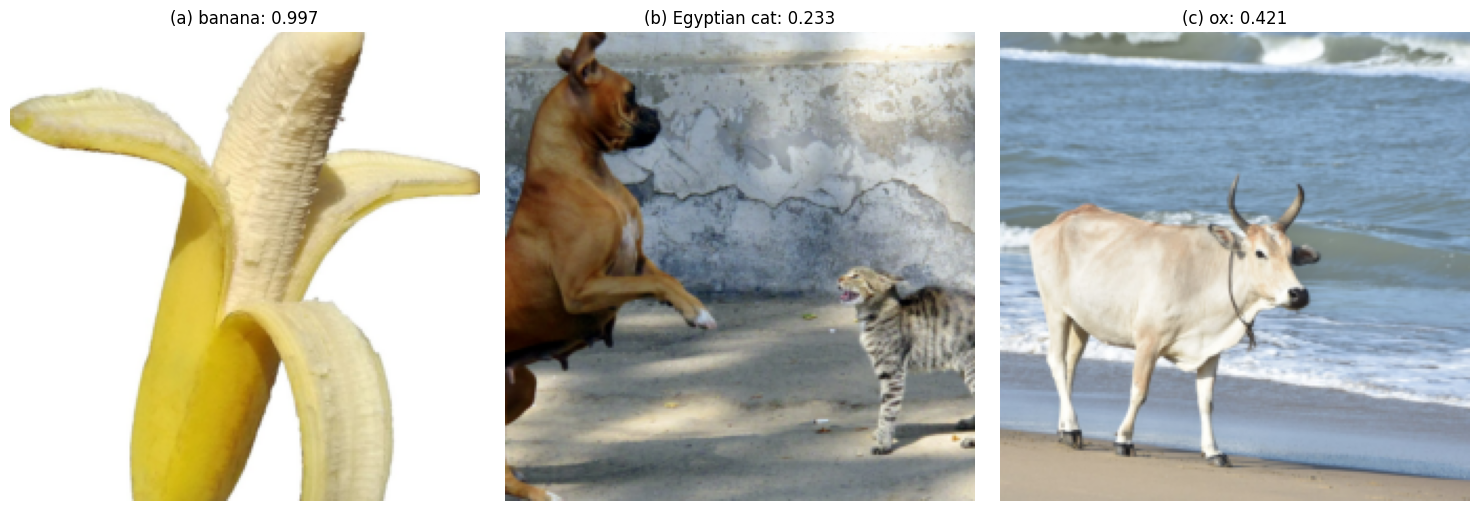

In [4]:
IMAGENES = {
    "a": {"archivo": "imagenes/imagen_a.jpg",
          "fuente": "Filo gèn', CC BY-SA 4.0, vía Wikimedia Commons — https://commons.wikimedia.org/wiki/File:Banana_on_whitebackground.jpg",
          "descripcion": "(a) objeto claro y centrado de una clase de ImageNet"},
    "b": {"archivo": "imagenes/imagen_b.jpg",
          "fuente": "Peretz Partensky, CC BY-SA 2.0, vía Wikimedia Commons — https://commons.wikimedia.org/wiki/File:Dog_and_cat_showing_fight_or_flight_responses.jpg",
          "descripcion": "(b) dos objetos de clases distintas (p. ej. gato y perro)"},
    "c": {"archivo": "imagenes/imagen_c.jpg",
          "fuente": "Timothy A. Gonsalves, CC BY-SA 4.0, vía Wikimedia Commons — https://commons.wikimedia.org/wiki/File:Cow_Uthandi_Beach_Chennai_Aug21_D72_20734.jpg",
          "descripcion": "(c) objeto sobre un fondo que puede engañar al modelo"},
}

def cargar_imagen(ref):
    if str(ref).startswith("http"):
        import requests
        r = requests.get(ref, headers={"User-Agent": "Mozilla/5.0 (laboratorio XAI UVG)"}, timeout=30)
        r.raise_for_status()
        return Image.open(io.BytesIO(r.content)).convert("RGB")
    return Image.open(ref).convert("RGB")

IMG = {}   # img_np (224,224,3) en [0,1]
X_IMG = {} # tensor normalizado (1,3,224,224)
for k, info in IMAGENES.items():
    pil = recorte_224(cargar_imagen(info["archivo"]))
    IMG[k] = np.asarray(pil, dtype=np.float32) / 255.0
    X_IMG[k] = a_tensor(IMG[k])

@torch.no_grad()
def predecir(x):
    logits = modelo(x)
    return logits[0], logits.softmax(dim=1)[0]

TOP1 = {}
RES["task1_1"] = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, k in zip(axes, IMAGENES):
    logits, probs = predecir(X_IMG[k])
    p5, i5 = probs.topk(5)
    TOP1[k] = int(i5[0])
    print(f"\nImagen {IMAGENES[k]['descripcion']}  |  fuente: {IMAGENES[k]['fuente']}")
    filas = []
    for r, (p, i) in enumerate(zip(p5.tolist(), i5.tolist()), 1):
        print(f"  {r}. [{i:4d}] {CATEGORIAS[i]:<30s} p = {p:.4f}")
        filas.append({"rango": r, "indice": i, "clase": CATEGORIAS[i], "prob": p})
    RES["task1_1"][k] = {"fuente": IMAGENES[k]["fuente"], "top5": filas}
    ax.imshow(IMG[k]); ax.axis("off")
    ax.set_title(f"({k}) {CATEGORIAS[i5[0]]}: {p5[0]:.3f}")
plt.tight_layout(); guardar_fig("t1_1_imagenes"); mostrar()

### Segunda clase de la imagen (b)
Por defecto se toma la clase más probable del otro grupo (si el top-1 es un gato, el perro más probable, y viceversa; en ImageNet los perros son los índices 151–268 y los gatos domésticos 281–285). Si sus objetos son otros, escriba a mano el índice en `CLASE_B2_MANUAL`.

In [5]:
CLASE_B2_MANUAL = None   # p. ej. 207 (golden retriever); None = selección automática

PERROS = list(range(151, 269))
GATOS = list(range(281, 286))

def elegir_segunda_clase(probs, c1):
    if CLASE_B2_MANUAL is not None:
        return int(CLASE_B2_MANUAL)
    if c1 in GATOS:
        rango = PERROS
    elif c1 in PERROS:
        rango = GATOS
    else:
        return int(probs.argsort(descending=True)[1])
    return rango[int(probs[rango].argmax())]

_, probs_b = predecir(X_IMG["b"])
C_B1 = TOP1["b"]
C_B2 = elegir_segunda_clase(probs_b, C_B1)
rango_b2 = int((probs_b > probs_b[C_B2]).sum()) + 1
print(f"Clase 1 de (b): [{C_B1}] {CATEGORIAS[C_B1]}  p = {probs_b[C_B1]:.4f}")
print(f"Clase 2 de (b): [{C_B2}] {CATEGORIAS[C_B2]}  p = {probs_b[C_B2]:.4f}  (rango {rango_b2} entre 1000)")
RES["task1_1"]["b_segunda_clase"] = {"indice": C_B2, "clase": CATEGORIAS[C_B2],
                                      "prob": float(probs_b[C_B2]), "rango": rango_b2}

Clase 1 de (b): [285] Egyptian cat  p = 0.2329
Clase 2 de (b): [243] bull mastiff  p = 0.0990  (rango 3 entre 1000)


### Recuadro del objeto en la imagen (c)
La cuadrícula marca cada 16 px de la imagen de 224×224. Lea las coordenadas y escríbalas en `BBOX_C = (x0, y0, x1, y1)`: `x` es la columna (horizontal) y `y` la fila (vertical); `x1`, `y1` son exclusivos.

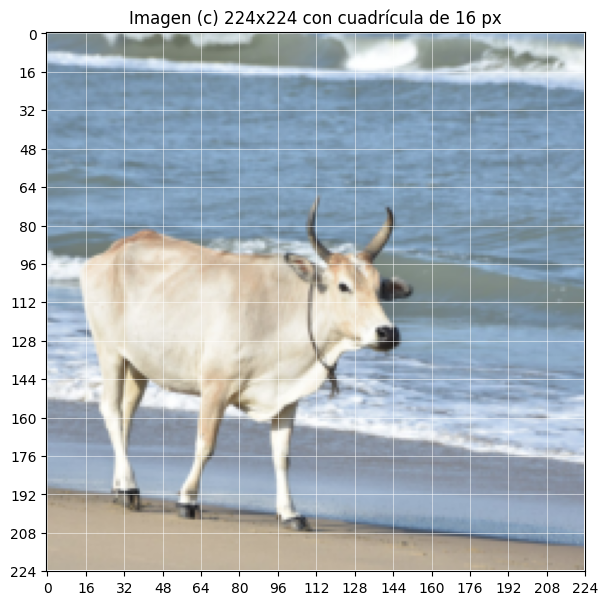

In [6]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(IMG["c"])
ax.set_xticks(range(0, 225, 16)); ax.set_yticks(range(0, 225, 16))
ax.grid(color="white", lw=0.5, alpha=0.7)
ax.set_title("Imagen (c) 224x224 con cuadrícula de 16 px")
mostrar()

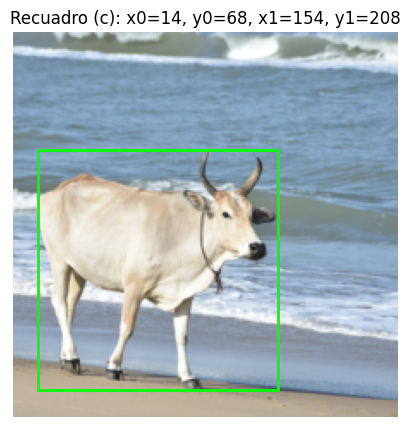

Fracción del área de la imagen que ocupa el recuadro: 0.390625


In [7]:
BBOX_C = (14, 68, 154, 208)

x0, y0, x1, y1 = BBOX_C
assert 0 <= x0 < x1 <= 224 and 0 <= y0 < y1 <= 224
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(IMG["c"])
ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=2))
ax.set_title(f"Recuadro (c): x0={x0}, y0={y0}, x1={x1}, y1={y1}"); ax.axis("off")
guardar_fig("t1_1_bbox_c"); mostrar()
RES["task1_1"]["bbox_c"] = {"x0": x0, "y0": y0, "x1": x1, "y1": y1,
                            "fraccion_area": (x1 - x0) * (y1 - y0) / 224**2}
print("Fracción del área de la imagen que ocupa el recuadro:", RES["task1_1"]["bbox_c"]["fraccion_area"])

## Task 1.2 — Grad-CAM desde cero sobre `layer4`
**[Diap. «Grad-CAM: mapas de activación sin cambiar la arquitectura»]** El gradiente $\partial y^c/\partial A^k$ se promedia espacialmente para obtener $\alpha_k^c$ y el mapa es $L^c=\mathrm{ReLU}\left(\sum_k \alpha_k^c A^k\right)$; no hace falta que la red termine en GAP.
- Hook de avance: guarda $A^k$ (512 canales de 7×7).
- Hook de retroceso: guarda $\partial y^c / \partial A$.
- Se retropropaga desde el **logit** $y^c$ (antes del softmax).
- $\alpha_k^c = \frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}}$ con $Z = 7\cdot 7 = 49$ (promedio espacial).
- $L^c = \mathrm{ReLU}\left(\sum_k \alpha_k^c A^k\right)$, se amplía a 224×224 con interpolación bilineal y se normaliza con mínimo y máximo.

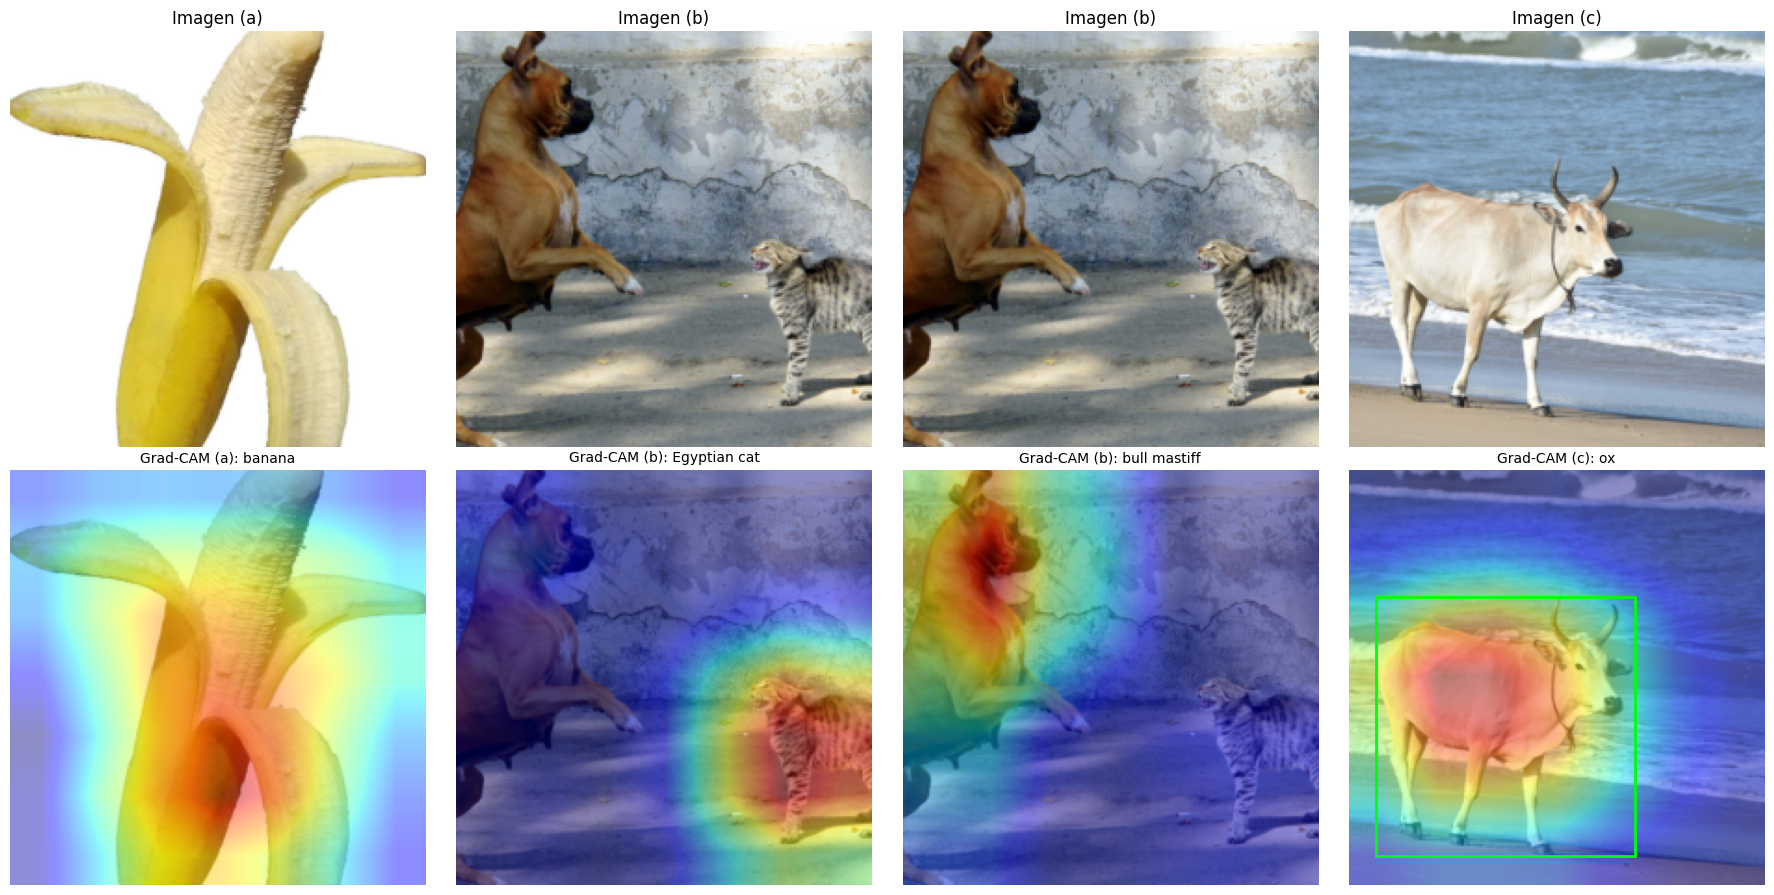

In [8]:
# [Diap. «Grad-CAM»] A^k = mapas de la última capa convolucional (layer4), y^c = score de la clase
class GradCAM:
    def __init__(self, red, capa):
        self.red = red
        self.A = None    # activaciones A^k_ij  -> (1, 512, 7, 7)
        self.dA = None   # gradientes dy^c/dA^k_ij -> (1, 512, 7, 7)
        self.h_fwd = capa.register_forward_hook(self._hook_avance)
        self.h_bwd = capa.register_full_backward_hook(self._hook_retroceso)

    def _hook_avance(self, modulo, entrada, salida):
        self.A = salida.detach()

    def _hook_retroceso(self, modulo, grad_entrada, grad_salida):
        # grad_salida[0] = dy^c / d(salida de layer4) = dy^c / dA
        self.dA = grad_salida[0].detach()

    def quitar(self):
        self.h_fwd.remove(); self.h_bwd.remove()

    def __call__(self, x, c):
        self.red.zero_grad(set_to_none=True)
        logits = self.red(x)            # y: logits (pre-softmax), el forward hook guarda A
        y_c = logits[0, c]
        y_c.backward()                  # retropropaga desde y^c, no desde la probabilidad ni una pérdida
        A, dA = self.A[0], self.dA[0]
        Z = A.shape[1] * A.shape[2]     # Z = 49 posiciones
        alpha = dA.mean(dim=(1, 2))     # [Diap. «Grad-CAM»] alpha_k^c = promedio espacial del gradiente = (1/Z) sum_ij dy^c/dA^k_ij
        L_lineal = (alpha[:, None, None] * A).sum(dim=0)   # sum_k alpha_k^c A^k  (sin ReLU)
        L_7 = F.relu(L_lineal)                              # [Diap. «Grad-CAM»] L^c = ReLU(sum_k alpha_k^c A^k)
        L_224 = F.interpolate(L_7[None, None], size=(224, 224), mode="bilinear",
                              align_corners=False)[0, 0]    # ampliación bilineal a 224x224
        L_224 = (L_224 - L_224.min()) / (L_224.max() - L_224.min() + 1e-12)  # min-max
        return {"logit": y_c.item(), "A": A, "dA": dA, "alpha": alpha, "Z": Z,
                "L_lineal": L_lineal.detach(), "L_7": L_7.detach(), "L_224": L_224.detach()}

gradcam = GradCAM(modelo, modelo.layer4)

def superponer(ax, img_np, mapa, titulo, bbox=None):
    ax.imshow(img_np)
    ax.imshow(mapa, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    if bbox is not None:
        x0, y0, x1, y1 = bbox
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=2))
    ax.set_title(titulo, fontsize=10); ax.axis("off")

# Mapas de la clase de mayor probabilidad de cada imagen + segunda clase de (b)
GC = {k: gradcam(X_IMG[k], TOP1[k]) for k in IMAGENES}
GC["b2"] = gradcam(X_IMG["b"], C_B2)

paneles = [("a", "a", TOP1["a"]), ("b", "b", TOP1["b"]), ("b", "b2", C_B2), ("c", "c", TOP1["c"])]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for col, (k_img, k_gc, c) in enumerate(paneles):
    axes[0, col].imshow(IMG[k_img]); axes[0, col].axis("off")
    axes[0, col].set_title(f"Imagen ({k_img})")
    superponer(axes[1, col], IMG[k_img], GC[k_gc]["L_224"].numpy(),
               f"Grad-CAM ({k_img}): {CATEGORIAS[c]}",
               bbox=BBOX_C if k_img == "c" else None)
plt.tight_layout(); guardar_fig("t1_2_gradcam"); mostrar()

## Task 1.3 — CAM desde los pesos de `fc` y relación con Grad-CAM
**[Diap. «CAM: del global average pooling al mapa de activación de clase»]** El GAP da $z_k=\frac{1}{HW}\sum_{i,j}A^k_{ij}$ y la capa lineal da el score $y^c=\sum_k w_k^c z_k + b_c$. En ResNet-18, $H=W=7$ y $Z=HW=49$. Sustituyendo:

ResNet-18 termina en `avgpool` (promedio global) y `fc`, así que
$y^c = \sum_k w_k^c \frac{1}{Z}\sum_{ij}A^k_{ij} + b_c = \frac{1}{Z}\sum_{ij} M^c_{ij} + b_c$ con $M^c_{ij}=\sum_k w^c_k A^k_{ij}$.

,mapa,clase,logit y^c,(1/Z)ΣM + b_c,|error| (b),máx|Z·L - M| (c),máx|error| ReLU+minmax 7x7 (d),máx|error| 224x224 (extra)
0,a,banana,18.67,18.67,1.90735e-06,7.62939e-06,2.98023e-07,5.36442e-07
1,b,Egyptian cat,10.074,10.074,0,7.62939e-06,1.78814e-07,3.57628e-07
2,b2,bull mastiff,9.21813,9.21813,0,4.76837e-06,1.78814e-07,2.38419e-07
3,c,ox,10.1828,10.1828,0,1.14441e-05,2.98023e-07,4.17233e-07


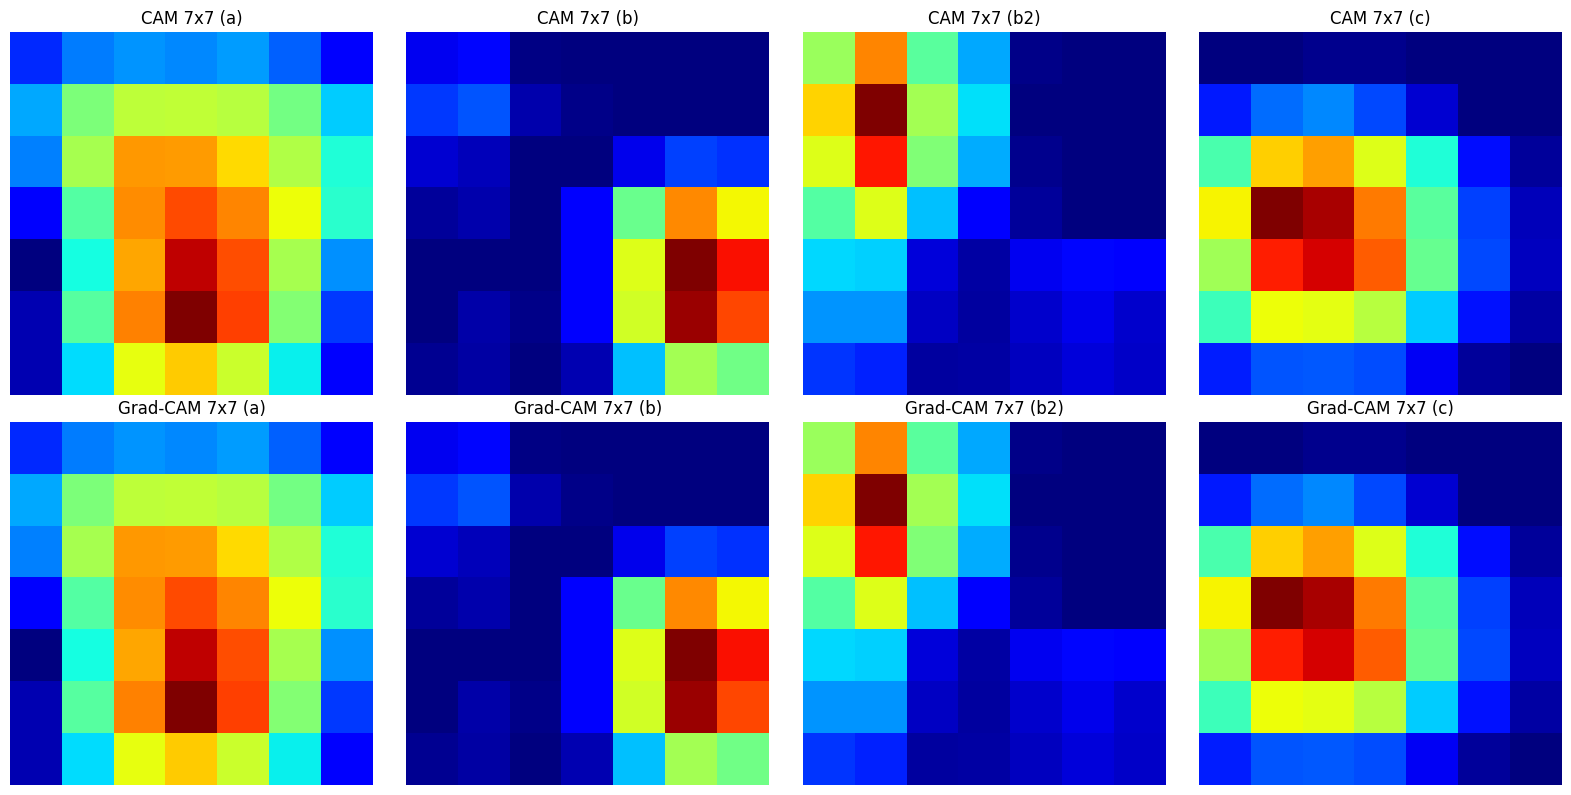

In [9]:
W_FC = modelo.fc.weight.detach()   # (1000, 512): w_k^c
B_FC = modelo.fc.bias.detach()     # (1000,):     b_c

def cam(x, c):
    """CAM sin gradientes: solo un forward para capturar A con el hook de avance."""
    with torch.no_grad():
        logits = modelo(x)
    A = gradcam.A[0]                                   # (512, 7, 7)
    # [Diap. «CAM»] M^c_ij = sum_k w_k^c · A^k_ij  (los mismos pesos de fc que convierten z_k en el score)
    M = torch.einsum("k,kij->ij", W_FC[c], A)
    return M, logits[0, c].item(), A

def relu_minmax(m):
    m = F.relu(m)
    return (m - m.min()) / (m.max() - m.min() + 1e-12)

def ampliar(m7):
    return F.interpolate(m7[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]

filas_13 = []
CAM = {}
for k_img, k_gc, c in [("a", "a", TOP1["a"]), ("b", "b", TOP1["b"]), ("b", "b2", C_B2), ("c", "c", TOP1["c"])]:
    M, logit, A = cam(X_IMG[k_img], c)
    CAM[k_gc] = M
    Z = 49
    # (b) descomposición del puntaje: (1/Z) sum_ij M_ij + b_c  ==  y^c
    puntaje = (M.sum() / Z + B_FC[c]).item()
    # (c) Grad-CAM sin ReLU ni normalización, por Z, frente a M
    L_lin = GC[k_gc]["L_lineal"]
    err_c = (Z * L_lin - M).abs().max().item()
    # (d) ReLU + min-max en ambos (7x7 y, como verificación extra, ampliados a 224)
    m_cam, m_gc = relu_minmax(M), relu_minmax(L_lin)
    err_d7 = (m_cam - m_gc).abs().max().item()
    err_d224 = (relu_minmax(ampliar(M)) - relu_minmax(ampliar(L_lin))).abs().max().item()
    filas_13.append({"mapa": k_gc, "clase": CATEGORIAS[c], "logit y^c": logit,
                     "(1/Z)ΣM + b_c": puntaje, "|error| (b)": abs(puntaje - logit),
                     "máx|Z·L - M| (c)": err_c, "máx|error| ReLU+minmax 7x7 (d)": err_d7,
                     "máx|error| 224x224 (extra)": err_d224})

tabla_13 = pd.DataFrame(filas_13)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
display(tabla_13)
RES["task1_3"] = tabla_13.to_dict(orient="records")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, k in enumerate(["a", "b", "b2", "c"]):
    axes[0, col].imshow(relu_minmax(CAM[k]).numpy(), cmap="jet"); axes[0, col].set_title(f"CAM 7x7 ({k})")
    axes[1, col].imshow(relu_minmax(GC[k]["L_lineal"]).numpy(), cmap="jet"); axes[1, col].set_title(f"Grad-CAM 7x7 ({k})")
    for r in range(2): axes[r, col].axis("off")
plt.tight_layout(); guardar_fig("t1_3_cam_vs_gradcam"); mostrar()

## Task 1.4 — Preguntas con base en los resultados
### 1.4a — $\alpha_k^c$ frente a $w_k^c/Z$ en la imagen (a)
Derivación (diapositivas «CAM» y «Grad-CAM»): $y^c=\sum_k w_k^c\,\frac{1}{Z}\sum_{i,j}A^k_{ij}+b_c \Rightarrow \frac{\partial y^c}{\partial A^k_{ij}}=\frac{w_k^c}{Z}$, que no depende de $(i,j)$ porque el GAP pesa igual todas las posiciones. Entonces $\alpha_k^c=\frac{1}{Z}\sum_{i,j}\frac{w_k^c}{Z}=\frac{w_k^c}{Z}$ y $Z\cdot L^c_{\text{sin ReLU}} = M^c$.
Además de float32 (precisión normal del modelo) se repite el cálculo en float64 para mostrar que el error baja al nivel de la precisión de máquina de float64: eso confirma que la diferencia es solo de redondeo.

In [10]:
c_a = TOP1["a"]
alpha32 = GC["a"]["alpha"]
w_Z = W_FC[c_a] / 49.0

# Grad-CAM con una copia del modelo en float64
modelo64 = copy.deepcopy(modelo).double().eval()
gradcam64 = GradCAM(modelo64, modelo64.layer4)
alpha64 = gradcam64(X_IMG["a"].double(), c_a)["alpha"]
w_Z64 = modelo64.fc.weight.detach()[c_a] / 49.0
gradcam64.quitar()

top5_canales = torch.argsort(W_FC[c_a], descending=True)[:5]
filas = []
for k in top5_canales.tolist():
    filas.append({"canal k": k, "w_k^c": W_FC[c_a, k].item(), "w_k^c/Z": w_Z[k].item(),
                  "alpha_k^c (float32)": alpha32[k].item(),
                  "error relativo float32": abs(alpha32[k] - w_Z[k]).item() / abs(w_Z[k]).item(),
                  "error relativo float64": abs(alpha64[k] - w_Z64[k]).item() / abs(w_Z64[k]).item()})
tabla_14a = pd.DataFrame(filas)
display(tabla_14a)

rel32 = ((alpha32 - w_Z).abs() / w_Z.abs().clamp_min(1e-12))
rel64 = ((alpha64 - w_Z64).abs() / w_Z64.abs().clamp_min(1e-300))
# Variación espacial del gradiente: si dy/dA_ij^k no depende de (i,j), la desviación estándar espacial es ~0
desv_espacial = GC["a"]["dA"].std(dim=(1, 2)).max().item()
print(f"Error relativo máximo en los 512 canales: float32 = {rel32.max():.3e} | float64 = {rel64.max():.3e}")
print(f"Épsilon de máquina: float32 = {torch.finfo(torch.float32).eps:.3e} | float64 = {torch.finfo(torch.float64).eps:.3e}")
print(f"Máxima desviación estándar espacial de dy^c/dA^k_ij entre canales: {desv_espacial:.3e}")
RES["task1_4a"] = {"tabla": tabla_14a.to_dict(orient="records"),
                   "max_rel_err_32": rel32.max().item(), "max_rel_err_64": rel64.max().item(),
                   "eps32": torch.finfo(torch.float32).eps, "eps64": torch.finfo(torch.float64).eps,
                   "max_std_espacial_grad": desv_espacial}

,canal k,w_k^c,w_k^c/Z,alpha_k^c (float32),error relativo float32,error relativo float64
0,171,0.332855,0.00679297,0.00679297,6.85505e-08,1.27685e-16
1,141,0.329215,0.00671867,0.00671867,6.93085e-08,1.29097e-16
2,496,0.302661,0.00617676,0.00617676,7.53892e-08,0
3,41,0.301633,0.00615577,0.00615577,7.56463e-08,0
4,226,0.300756,0.00613788,0.00613788,7.58668e-08,1.41313e-16


Error relativo máximo en los 512 canales: float32 = 2.345e-07 | float64 = 2.532e-16
Épsilon de máquina: float32 = 1.192e-07 | float64 = 2.220e-16
Máxima desviación estándar espacial de dy^c/dA^k_ij entre canales: 0.000e+00


### 1.4b — IoU entre los mapas de las dos clases de la imagen (b)
Se toma el 20 % de píxeles de mayor valor en cada mapa de 224×224 (por rango, para tener exactamente el 20 %). Como referencia extra se repite sobre la rejilla original de 7×7 (10 de 49 celdas ≈ 20 %).

IoU top-20% (224x224): 0.0000
IoU top-20% (7x7, extra): 0.0000
Spearman entre los dos mapas 7x7 (extra): -0.0439
Cada celda de la rejilla 7x7 corresponde a 224/7 = 32 x 32 píxeles de entrada.


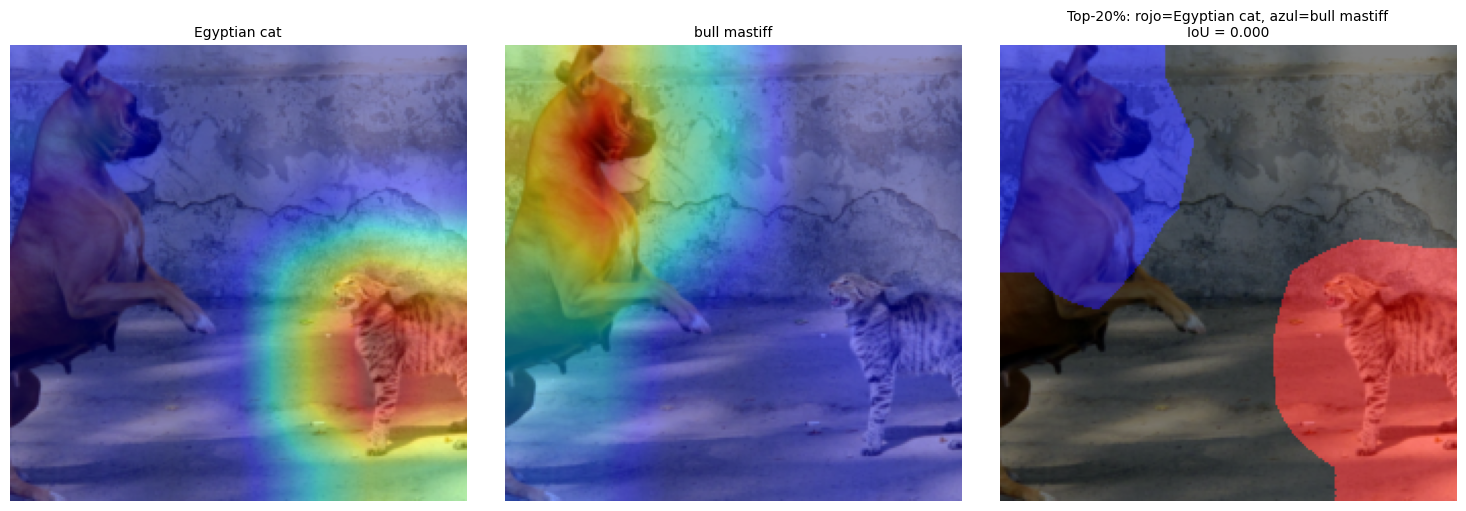

In [11]:
def mascara_top(mapa, frac=0.20):
    v = mapa.flatten()
    n = int(round(frac * v.numel()))
    idx = torch.argsort(v, descending=True)[:n]
    m = torch.zeros_like(v, dtype=torch.bool); m[idx] = True
    return m.reshape(mapa.shape)

def iou(m1, m2):
    return (m1 & m2).sum().item() / (m1 | m2).sum().item()

m1, m2 = mascara_top(GC["b"]["L_224"]), mascara_top(GC["b2"]["L_224"])
iou_224 = iou(m1, m2)
iou_7 = iou(mascara_top(GC["b"]["L_7"]), mascara_top(GC["b2"]["L_7"]))
corr_mapas = spearmanr(GC["b"]["L_7"].flatten(), GC["b2"]["L_7"].flatten())[0]
print(f"IoU top-20% (224x224): {iou_224:.4f}")
print(f"IoU top-20% (7x7, extra): {iou_7:.4f}")
print(f"Spearman entre los dos mapas 7x7 (extra): {corr_mapas:.4f}")
print("Cada celda de la rejilla 7x7 corresponde a 224/7 = 32 x 32 píxeles de entrada.")
RES["task1_4b"] = {"iou_224": iou_224, "iou_7x7": iou_7, "spearman_mapas_7x7": corr_mapas,
                   "clase1": CATEGORIAS[C_B1], "clase2": CATEGORIAS[C_B2]}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
superponer(axes[0], IMG["b"], GC["b"]["L_224"].numpy(), f"{CATEGORIAS[C_B1]}")
superponer(axes[1], IMG["b"], GC["b2"]["L_224"].numpy(), f"{CATEGORIAS[C_B2]}")
rgb = np.zeros((224, 224, 3)); rgb[..., 0] = m1.numpy(); rgb[..., 2] = m2.numpy()
axes[2].imshow(IMG["b"]); axes[2].imshow(rgb, alpha=0.5); axes[2].axis("off")
axes[2].set_title(f"Top-20%: rojo={CATEGORIAS[C_B1]}, azul={CATEGORIAS[C_B2]}\nIoU = {iou_224:.3f}", fontsize=10)
plt.tight_layout(); guardar_fig("t1_4b_iou"); mostrar()

### 1.4c — Masa del mapa dentro del recuadro y prueba causal en la imagen (c)
- Fracción de masa: $\sum_{(i,j)\in\text{recuadro}} L^c_{ij} / \sum_{i,j} L^c_{ij}$ con el mapa normalizado de 224×224 (se compara con la fracción de área del recuadro, que sería la masa de un mapa uniforme).
- Prueba causal: se reemplaza por gris medio (0.5 en cada canal, antes de normalizar) todo lo que queda fuera del recuadro y se mide el cambio en $p(c)$.
- Prueba extra (complementaria): se deja solo el fondo (gris dentro del recuadro) para ver cuánta probabilidad sostiene el fondo por sí solo.

Clase: [345] ox
Fracción de la masa del mapa dentro del recuadro: 0.7447  (fracción de área: 0.3906)
p(clase) original:                  0.4210
p(clase) fondo gris (solo objeto):  0.2861  -> cambio -0.1349  | top-1: oxcart (0.411)
p(clase) objeto gris (solo fondo):  0.0001  -> cambio -0.4210  | top-1: seashore (0.326)


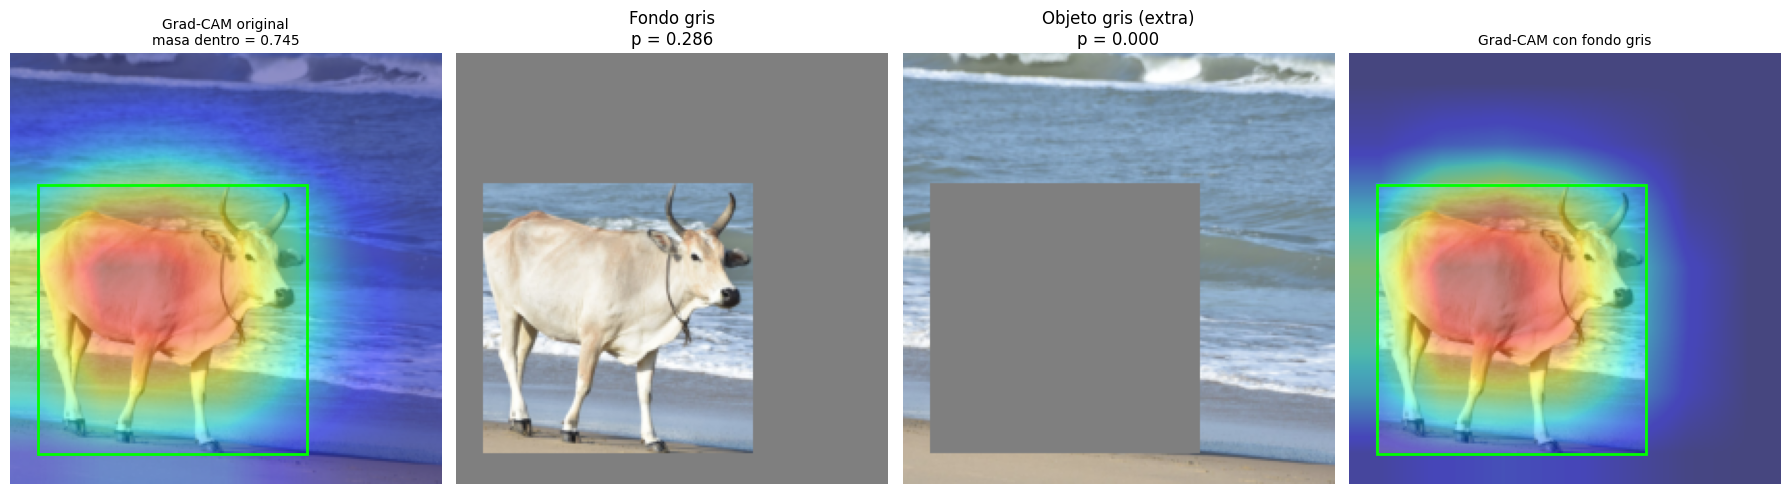

In [12]:
c_c = TOP1["c"]
x0, y0, x1, y1 = BBOX_C
L = GC["c"]["L_224"]
masa_dentro = (L[y0:y1, x0:x1].sum() / L.sum()).item()
frac_area = (x1 - x0) * (y1 - y0) / 224**2

GRIS = 0.5
img_solo_objeto = np.full_like(IMG["c"], GRIS); img_solo_objeto[y0:y1, x0:x1] = IMG["c"][y0:y1, x0:x1]
img_solo_fondo = IMG["c"].copy(); img_solo_fondo[y0:y1, x0:x1] = GRIS

_, p_orig = predecir(X_IMG["c"])
_, p_obj = predecir(a_tensor(img_solo_objeto))
_, p_fondo = predecir(a_tensor(img_solo_fondo))

def top1_txt(p):
    i = int(p.argmax()); return f"{CATEGORIAS[i]} ({p[i]:.3f})"

print(f"Clase: [{c_c}] {CATEGORIAS[c_c]}")
print(f"Fracción de la masa del mapa dentro del recuadro: {masa_dentro:.4f}  (fracción de área: {frac_area:.4f})")
print(f"p(clase) original:                  {p_orig[c_c]:.4f}")
print(f"p(clase) fondo gris (solo objeto):  {p_obj[c_c]:.4f}  -> cambio {p_obj[c_c] - p_orig[c_c]:+.4f}  | top-1: {top1_txt(p_obj)}")
print(f"p(clase) objeto gris (solo fondo):  {p_fondo[c_c]:.4f}  -> cambio {p_fondo[c_c] - p_orig[c_c]:+.4f}  | top-1: {top1_txt(p_fondo)}")
RES["task1_4c"] = {"clase": CATEGORIAS[c_c], "masa_dentro": masa_dentro, "fraccion_area": frac_area,
                   "p_original": p_orig[c_c].item(), "p_solo_objeto": p_obj[c_c].item(),
                   "p_solo_fondo": p_fondo[c_c].item(),
                   "top1_solo_objeto": top1_txt(p_obj), "top1_solo_fondo": top1_txt(p_fondo)}

GC_obj = gradcam(a_tensor(img_solo_objeto), c_c)
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
superponer(axes[0], IMG["c"], L.numpy(), f"Grad-CAM original\nmasa dentro = {masa_dentro:.3f}", bbox=BBOX_C)
axes[1].imshow(img_solo_objeto); axes[1].axis("off"); axes[1].set_title(f"Fondo gris\np = {p_obj[c_c]:.3f}")
axes[2].imshow(img_solo_fondo); axes[2].axis("off"); axes[2].set_title(f"Objeto gris (extra)\np = {p_fondo[c_c]:.3f}")
superponer(axes[3], img_solo_objeto, GC_obj["L_224"].numpy(), "Grad-CAM con fondo gris", bbox=BBOX_C)
plt.tight_layout(); guardar_fig("t1_4c_prueba_causal"); mostrar()

---
# Task 2 — SHAP sobre un modelo de crédito (German Credit)
## Task 2.1 — Datos, codificación y modelo
**Limitación de la codificación ordinal:** los códigos de las variables categóricas son arbitrarios (orden alfabético de las categorías), pero el gradient boosting los trata como números y hace cortes del tipo `código ≤ t`. Eso impone un orden que no existe (por ejemplo, entre propósitos del crédito) y obliga a los árboles a juntar categorías vecinas por código; los valores SHAP de esas variables se interpretan por categoría, no como "más es mejor".

In [13]:
datos = fetch_openml("credit-g", version=1, as_frame=True)
df = datos.frame.copy()
X_raw = df.drop(columns="class")
y = (df["class"] == "good").astype(int)          # good = 1, bad = 0
COLS = list(X_raw.columns)
CAT_COLS = [c for c in COLS if not pd.api.types.is_numeric_dtype(X_raw[c])]
NUM_COLS = [c for c in COLS if c not in CAT_COLS]
print(f"{X_raw.shape[0]} solicitudes, {len(COLS)} variables: {len(NUM_COLS)} numéricas y {len(CAT_COLS)} categóricas")
print("Numéricas:", NUM_COLS)
print("Proporción de good:", y.mean())

# Codificador ordinal: códigos 0..m-1 en orden alfabético. Es solo un mapeo (no usa la etiqueta),
# por eso se ajusta sobre todas las filas; se guarda para decodificar después.
codificador = OrdinalEncoder()
X = X_raw.copy()
X[CAT_COLS] = codificador.fit_transform(X_raw[CAT_COLS].astype(str))
X = X.astype(float)
CATEGORIAS_ORD = dict(zip(CAT_COLS, codificador.categories_))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_test_raw = X_raw.loc[X_test.index]
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

def nuevo_gb():
    return GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED)

modelo_gb = nuevo_gb().fit(X_train, y_train)
p_test = modelo_gb.predict_proba(X_test)[:, 1]
acc = accuracy_score(y_test, (p_test >= 0.5).astype(int))
auc = roc_auc_score(y_test, p_test)
print(f"Exactitud (prueba): {acc:.4f} | AUC (prueba): {auc:.4f}")
RES["task2_1"] = {"exactitud": acc, "auc": auc, "n_train": len(X_train), "n_test": len(X_test)}

1000 solicitudes, 20 variables: 7 numéricas y 13 categóricas
Numéricas: ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Proporción de good: 0.7
Entrenamiento: (800, 20) | Prueba: (200, 20)
Exactitud (prueba): 0.7750 | AUC (prueba): 0.7650


## Task 2.2 — TreeSHAP intervencional en log-odds
**[Diap. «SHAP en la práctica»]** Atribución aditiva $f(x)=\phi_0+\sum_i\phi_i$ con $\phi_0=\mathbb E[f(X)]$; aquí la esperanza se toma sobre el fondo de 100 instancias. TreeSHAP es exacto y polinomial para árboles. Local: cascada; global: promedio de $|\phi_i|$ y beeswarm.
`model_output="raw"` en un `GradientBoostingClassifier` binario es la salida en log-odds, igual a `decision_function`.

In [14]:
rng_fondo = np.random.default_rng(SEED)
IDX_FONDO = X_train.index[rng_fondo.choice(len(X_train), size=100, replace=False)]
fondo = X_train.loc[IDX_FONDO]

# [Diap. «SHAP en la práctica»] TreeSHAP intervencional: las variables ausentes se toman del fondo
# ("el conjunto de fondo y cómo se simulan las features ausentes cambian los valores")
explicador = shap.TreeExplainer(modelo_gb, data=fondo,
                                feature_perturbation="interventional", model_output="raw")
sv = explicador(X_test)                      # Explanation: values (200, 20), base_values
PHI = sv.values
PHI0 = float(np.ravel(explicador.expected_value)[0])
f_test = modelo_gb.decision_function(X_test)  # log-odds

# (a) [Diap. «SHAP en la práctica»] eficiencia: f(x) = phi_0 + sum_j phi_j
err_ef = np.abs(PHI0 + PHI.sum(axis=1) - f_test).max()
# (b) [Diap. «SHAP en la práctica»] phi_0 = E[f(X)], estimado como el promedio de f sobre el fondo
f_fondo_media = modelo_gb.decision_function(fondo).mean()
print(f"(a) Error absoluto máximo de eficiencia: {err_ef:.3e}")
print(f"(b) Valor base phi_0 = {PHI0:.6f} | promedio de f(x) en el fondo = {f_fondo_media:.6f} | diferencia = {abs(PHI0 - f_fondo_media):.3e}")
RES["task2_2"] = {"err_eficiencia_max": err_ef, "phi0": PHI0, "media_f_fondo": f_fondo_media}

(a) Error absoluto máximo de eficiencia: 9.722e-08
(b) Valor base phi_0 = 1.430742 | promedio de f(x) en el fondo = 1.430742 | diferencia = 0.000e+00


In [15]:
# (c) [Diap. «El mapa de tipos de explicación»] dos explicaciones globales agnósticas:
#     SHAP global I_j = (1/N) sum_n |phi_j^(n)|  vs  importancia por permutación (AUC, 10 repeticiones)
I = pd.Series(np.abs(PHI).mean(axis=0), index=COLS, name="I_j")
perm = permutation_importance(modelo_gb, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=SEED)
PERM = pd.Series(perm.importances_mean, index=COLS, name="perm_AUC")
PERM_STD = pd.Series(perm.importances_std, index=COLS, name="perm_std")

rho_rank = spearmanr(I.values, PERM.values)[0]
print("Top 5 por I_j (SHAP):"); display(I.sort_values(ascending=False).head(5).to_frame())
print("Top 5 por permutación (caída de AUC):")
display(pd.concat([PERM, PERM_STD], axis=1).sort_values("perm_AUC", ascending=False).head(5))
print(f"Spearman entre los dos rankings completos (20 variables): {rho_rank:.4f}")

tabla_imp = pd.DataFrame({"I_j": I, "rank_SHAP": I.rank(ascending=False).astype(int),
                          "perm_AUC": PERM, "perm_std": PERM_STD,
                          "rank_perm": PERM.rank(ascending=False).astype(int)}).sort_values("rank_SHAP")
display(tabla_imp)
RES["task2_2"].update({"top5_shap": I.sort_values(ascending=False).head(5).to_dict(),
                       "top5_perm": PERM.sort_values(ascending=False).head(5).to_dict(),
                       "spearman_rankings": rho_rank, "tabla_importancias": tabla_imp.to_dict(orient="index")})

Top 5 por I_j (SHAP):


,I_j
checking_status,0.760287
purpose,0.511731
credit_amount,0.490213
duration,0.391748
savings_status,0.296328


Top 5 por permutación (caída de AUC):


,perm_AUC,perm_std
checking_status,0.119,0.0301472
credit_amount,0.07625,0.0136109
duration,0.0579048,0.0119394
credit_history,0.0396429,0.0112254
savings_status,0.0261548,0.0112148


Spearman entre los dos rankings completos (20 variables): 0.6496


,I_j,rank_SHAP,perm_AUC,perm_std,rank_perm
checking_status,0.760287,1,0.119,0.0301472,1
purpose,0.511731,2,0.00375,0.0106576,12
credit_amount,0.490213,3,0.07625,0.0136109,2
duration,0.391748,4,0.0579048,0.0119394,3
savings_status,0.296328,5,0.0261548,0.0112148,5
age,0.288543,6,-0.00541667,0.00960711,20
credit_history,0.227802,7,0.0396429,0.0112254,4
residence_since,0.207859,8,0.00220238,0.0133918,13
installment_commitment,0.198319,9,0.0100238,0.00485936,7
other_payment_plans,0.174898,10,0.020119,0.00339275,6


### 2.2d — Cliente aprobado y cliente rechazado
Regla de selección (determinística): entre los clientes de prueba con $p(\text{good})>0.8$ se toma el de menor probabilidad, y entre los de $p<0.2$ el de mayor probabilidad; es decir, los más cercanos a cada umbral, que son los casos donde una explicación es más útil. El rechazado se reutiliza en los Task 2.6, 3 y 4.

Clientes con p>0.8: 93 | con p<0.2: 15
Aprobado:  posición 30 en prueba (índice 133), p = 0.8108, y real = 1
Rechazado: posición 75 en prueba (índice 876), p = 0.1944, y real = 1

Cliente aprobado: f(x) = 1.4554 log-odds, p(good) = 0.8108


,variable,valor,phi (log-odds),efecto
0,checking_status,no checking,0.884539,sube p(good)
12,age,47,0.83295,sube p(good)
13,other_payment_plans,bank,-0.472101,baja p(good)


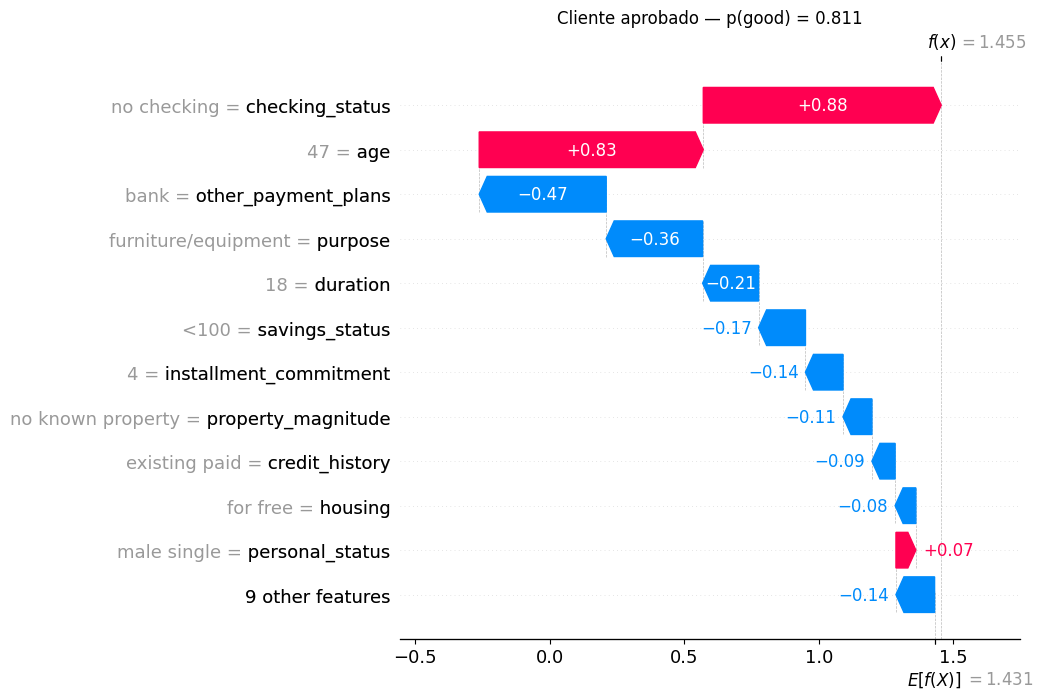


Cliente rechazado: f(x) = -1.4214 log-odds, p(good) = 0.1944


,variable,valor,phi (log-odds),efecto
2,credit_history,all paid,-0.937873,baja p(good)
0,checking_status,<0,-0.837452,baja p(good)
1,duration,18,-0.394438,baja p(good)


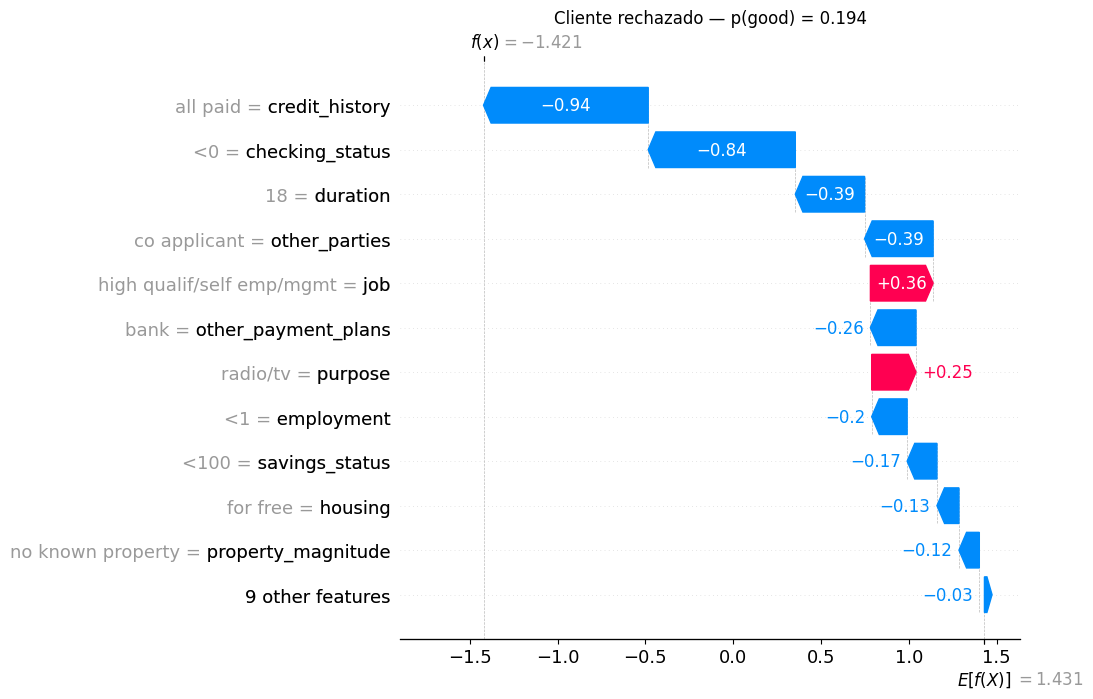

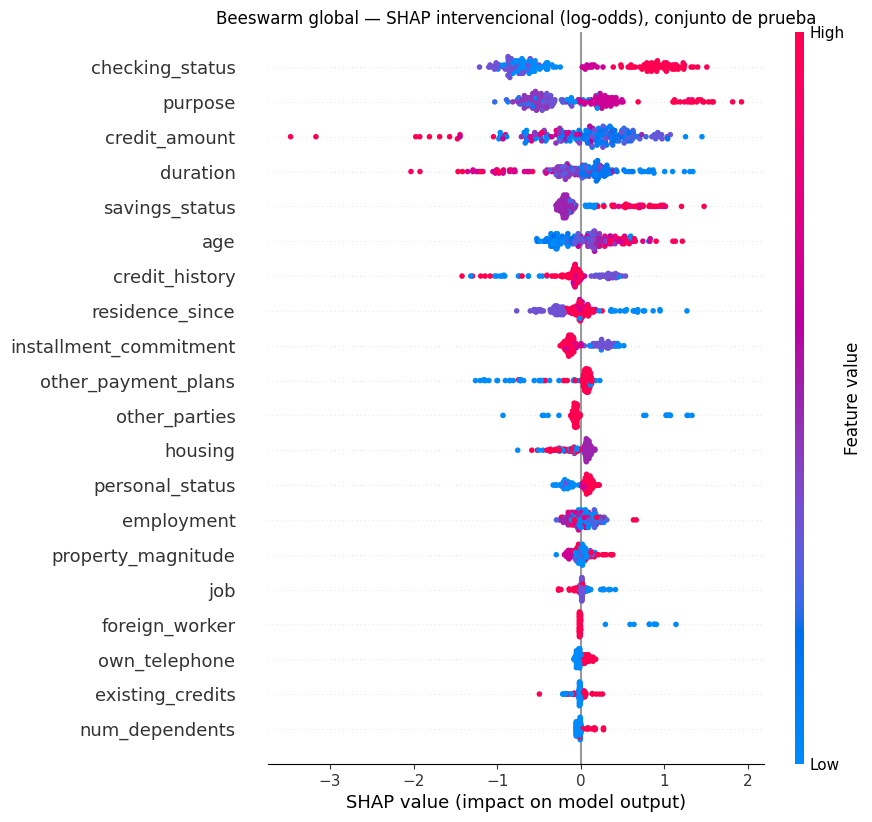

In [16]:
pos_aprob = np.where(p_test > 0.8)[0]
pos_rech = np.where(p_test < 0.2)[0]
POS_APROBADO = int(pos_aprob[np.argmin(p_test[pos_aprob])])
POS_RECHAZADO = int(pos_rech[np.argmax(p_test[pos_rech])])
ID_APROBADO, ID_RECHAZADO = X_test.index[POS_APROBADO], X_test.index[POS_RECHAZADO]
print(f"Clientes con p>0.8: {len(pos_aprob)} | con p<0.2: {len(pos_rech)}")
print(f"Aprobado:  posición {POS_APROBADO} en prueba (índice {ID_APROBADO}), p = {p_test[POS_APROBADO]:.4f}, y real = {y_test.iloc[POS_APROBADO]}")
print(f"Rechazado: posición {POS_RECHAZADO} en prueba (índice {ID_RECHAZADO}), p = {p_test[POS_RECHAZADO]:.4f}, y real = {y_test.iloc[POS_RECHAZADO]}")

def explicacion_legible(pos):
    """Explanation con los valores originales (categorías decodificadas) para mostrar en el waterfall."""
    e = sv[pos]
    disp = np.array([X_test_raw.iloc[pos][c] for c in COLS], dtype=object)
    return shap.Explanation(values=e.values, base_values=e.base_values, data=e.data,
                            display_data=disp, feature_names=COLS)

def tabla_contribuciones(pos, n=3):
    t = pd.DataFrame({"variable": COLS, "valor": [X_test_raw.iloc[pos][c] for c in COLS],
                      "phi (log-odds)": PHI[pos]})
    t["efecto"] = np.where(t["phi (log-odds)"] > 0, "sube p(good)", "baja p(good)")
    return t.reindex(t["phi (log-odds)"].abs().sort_values(ascending=False).index).head(n)

RES["task2_2"]["clientes"] = {}
for nombre, pos in [("aprobado", POS_APROBADO), ("rechazado", POS_RECHAZADO)]:
    print(f"\nCliente {nombre}: f(x) = {f_test[pos]:.4f} log-odds, p(good) = {p_test[pos]:.4f}")
    t3 = tabla_contribuciones(pos)
    display(t3)
    plt.figure()
    shap.plots.waterfall(explicacion_legible(pos), max_display=12, show=False)
    plt.title(f"Cliente {nombre} — p(good) = {p_test[pos]:.3f}")
    guardar_fig(f"t2_2d_waterfall_{nombre}"); mostrar()
    RES["task2_2"]["clientes"][nombre] = {"posicion": pos, "indice": int(X_test.index[pos]),
                                         "f_x": f_test[pos], "p_good": p_test[pos],
                                         "y_real": int(y_test.iloc[pos]),
                                         "top3": t3.astype({"valor": str}).to_dict(orient="records"),
                                         "phi_todas": dict(zip(COLS, PHI[pos])),
                                         "valores": {c: str(X_test_raw.iloc[pos][c]) for c in COLS}}

plt.figure()
shap.plots.beeswarm(sv, max_display=20, show=False)
plt.title("Beeswarm global — SHAP intervencional (log-odds), conjunto de prueba")
guardar_fig("t2_2d_beeswarm"); mostrar()

## Task 2.3 — SHAP con una variable redundante
$x_{dup} = x + 0.05\,\sigma_x\,\epsilon$, $\epsilon\sim\mathcal N(0,1)$, sobre la variable numérica de mayor $I_j$. Se reentrena con las mismas filas de entrenamiento/prueba, la misma semilla y el mismo fondo.

In [17]:
VAR_TOP = I.loc[NUM_COLS].idxmax()
VAR_COPIA = VAR_TOP + "_copia"
sigma_x = X[VAR_TOP].std()
rng_dup = np.random.default_rng(SEED)
X_dup = X.copy()
X_dup[VAR_COPIA] = X[VAR_TOP] + 0.05 * sigma_x * rng_dup.standard_normal(len(X))
Xtr_d, Xte_d = X_dup.loc[X_train.index], X_dup.loc[X_test.index]
corr_copia = np.corrcoef(X_dup[VAR_TOP], X_dup[VAR_COPIA])[0, 1]
print(f"Variable numérica de mayor I_j: {VAR_TOP} (I_j = {I[VAR_TOP]:.4f}), sigma = {sigma_x:.3f}")
print(f"Correlación de Pearson entre la variable y su copia: {corr_copia:.5f}")

modelo_dup = nuevo_gb().fit(Xtr_d, y_train)
p_dup = modelo_dup.predict_proba(Xte_d)[:, 1]
print(f"Modelo con 21 variables -> exactitud {accuracy_score(y_test, p_dup >= 0.5):.4f}, AUC {roc_auc_score(y_test, p_dup):.4f}")

# Configuración 1: intervencional con el mismo fondo de 100 instancias
exp_int_d = shap.TreeExplainer(modelo_dup, data=Xtr_d.loc[IDX_FONDO],
                               feature_perturbation="interventional", model_output="raw")
phi_int_d = exp_int_d.shap_values(Xte_d)
# Configuración 2: dependiente de la trayectoria del árbol (sin fondo; usa los conteos de los nodos)
exp_tpd_d = shap.TreeExplainer(modelo_dup, feature_perturbation="tree_path_dependent")
phi_tpd_d = exp_tpd_d.shap_values(Xte_d)
# Referencia: el modelo original (sin copia) en ambas configuraciones
phi_tpd_orig = shap.TreeExplainer(modelo_gb, feature_perturbation="tree_path_dependent").shap_values(X_test)

j_o, j_c = list(X_dup.columns).index(VAR_TOP), list(X_dup.columns).index(VAR_COPIA)
j_ref = COLS.index(VAR_TOP)
filas = []
for nombre, ph, ph_ref in [("intervencional (fondo 100)", phi_int_d, PHI),
                           ("tree_path_dependent", phi_tpd_d, phi_tpd_orig)]:
    filas.append({"configuración": nombre,
                  f"mean|φ {VAR_TOP}|": np.abs(ph[:, j_o]).mean(),
                  "mean|φ copia|": np.abs(ph[:, j_c]).mean(),
                  "mean|φ orig + φ copia|": np.abs(ph[:, j_o] + ph[:, j_c]).mean(),
                  "I_j sin copia (misma config.)": np.abs(ph_ref[:, j_ref]).mean()})
tabla_23 = pd.DataFrame(filas)
display(tabla_23)
print(f"I_j de {VAR_TOP} en el modelo sin copia (Task 2.2, intervencional): {I[VAR_TOP]:.4f}")

# Evidencia extra para 2.6c: cuántos cortes de los 200 árboles usan cada una de las dos columnas
def contar_cortes(gb, j):
    return sum(int((est.tree_.feature == j).sum()) for est in gb.estimators_.ravel())
cortes = {VAR_TOP: contar_cortes(modelo_dup, j_o), VAR_COPIA: contar_cortes(modelo_dup, j_c),
          f"{VAR_TOP} (modelo sin copia)": contar_cortes(modelo_gb, j_ref)}
print("Número de cortes en los árboles:", cortes)
corr_phi = np.corrcoef(phi_int_d[:, j_o], phi_int_d[:, j_c])[0, 1]
print(f"Correlación entre φ_orig y φ_copia (intervencional): {corr_phi:.4f}")
RES["task2_3"] = {"variable": VAR_TOP, "sigma": sigma_x, "corr_copia": corr_copia,
                  "tabla": tabla_23.to_dict(orient="records"), "I_j_sin_copia": I[VAR_TOP],
                  "cortes": cortes, "corr_phi_orig_copia": corr_phi,
                  "auc_dup": roc_auc_score(y_test, p_dup)}

Variable numérica de mayor I_j: credit_amount (I_j = 0.4902), sigma = 2822.737
Correlación de Pearson entre la variable y su copia: 0.99878
Modelo con 21 variables -> exactitud 0.7600, AUC 0.7671


,configuración,mean|φ credit_amount|,mean|φ copia|,mean|φ orig + φ copia|,I_j sin copia (misma config.)
0,intervencional (fondo 100),0.517996,0.42849,0.546026,0.490213
1,tree_path_dependent,0.381356,0.362974,0.530819,0.473795


I_j de credit_amount en el modelo sin copia (Task 2.2, intervencional): 0.4902
Número de cortes en los árboles: {'credit_amount': 156, 'credit_amount_copia': 210, 'credit_amount (modelo sin copia)': 285}
Correlación entre φ_orig y φ_copia (intervencional): -0.3007


## Task 2.4 — KernelSHAP frente a TreeSHAP
**[Diap. «SHAP en la práctica»]** KernelSHAP es agnóstico y estima los $\phi_i$ con una regresión ponderada sobre coaliciones muestreadas; TreeSHAP es exacto para árboles. Con el mismo fondo, ambos estiman los mismos valores, así que la diferencia es error de muestreo de KernelSHAP.
10 instancias de prueba (las 10 primeras), 2000 muestras por instancia, salida en log-odds. Los fondos de 10 y 50 son los primeros 10 y 50 del fondo de 100, para que estén anidados. Se usa `l1_reg=False` para que KernelSHAP estime todos los $\phi_j$ sin selección de variables.

In [18]:
X10 = X_test.iloc[:10]

def f_logodds(Zm):
    # KernelSHAP pasa matrices de NumPy; se reconstruye el DataFrame con los nombres de columnas
    return modelo_gb.decision_function(pd.DataFrame(Zm, columns=COLS))

filas, PHI_K = [], {}
for B in [10, 50, 100]:
    fondo_B = fondo.iloc[:B]
    np.random.seed(SEED)                         # KernelSHAP muestrea coaliciones con np.random
    t0 = time.perf_counter()
    # [Diap. «SHAP en la práctica»] KernelSHAP: muestrea 2000 coaliciones z' y ajusta una regresión ponderada;
    # cada coalición se evalúa promediando f sobre las B filas del fondo -> ~2000·B evaluaciones del modelo
    ke = shap.KernelExplainer(f_logodds, fondo_B.values)
    phi_k = np.array(ke.shap_values(X10.values, nsamples=2000, l1_reg=False, silent=True))
    t_kernel = time.perf_counter() - t0

    t0 = time.perf_counter()
    te = shap.TreeExplainer(modelo_gb, data=fondo_B, feature_perturbation="interventional", model_output="raw")
    phi_t = te.shap_values(X10)
    t_tree = time.perf_counter() - t0

    PHI_K[B] = phi_k
    filas.append({"fondo": B, "MAE Kernel vs Tree": np.abs(phi_k - phi_t).mean(),
                  "error máx": np.abs(phi_k - phi_t).max(),
                  "tiempo KernelSHAP (s)": t_kernel, "tiempo TreeSHAP (s)": t_tree,
                  "Kernel s/instancia": t_kernel / len(X10),
                  "evaluaciones ≈ muestras×fondo": 2000 * B})
tabla_24 = pd.DataFrame(filas)
display(tabla_24)
RES["task2_4"] = tabla_24.to_dict(orient="records")

,fondo,MAE Kernel vs Tree,error máx,tiempo KernelSHAP (s),tiempo TreeSHAP (s),Kernel s/instancia,evaluaciones ≈ muestras×fondo
0,10,0.00240359,0.0170186,0.446288,0.0053962,0.0446288,20000
1,50,0.0049301,0.0477595,1.41764,0.0120987,0.141764,100000
2,100,0.00436237,0.044183,2.74432,0.0200961,0.274432,200000


## Task 2.5 — Shapley exacto escrito a mano (6 variables numéricas)
**[Diap. «Valores de Shapley: repartir el mérito de una predicción»]** $\phi_i$ es el promedio de los aportes marginales $v(S\cup\{i\})-v(S)$ sobre todos los órdenes de llegada. El peso $\frac{|S|!\,(n-|S|-1)!}{n!}$ es la fracción de los $n!$ órdenes en los que llegan primero exactamente las variables de $S$ y luego $i$. Se calcula con la fórmula por coaliciones (lo que pide la tarea) y, como verificación extra, con el promedio sobre los $6!=720$ órdenes, como en la diapositiva.

**[Diap. «SHAP en la práctica»]** El cálculo exacto requiere $2^n$ coaliciones.
$v(S) = \frac{1}{|\text{fondo}|}\sum_{r\in\text{fondo}} f(x_S, r_{\bar S})$ (log-odds) y
$\phi_i = \sum_{S\subseteq N\setminus\{i\}} \frac{|S|!\,(n-|S|-1)!}{n!}\,\big[v(S\cup\{i\}) - v(S)\big]$, con $n=6$ y $2^6=64$ coaliciones.

In [19]:
NUM6 = ["duration", "credit_amount", "installment_commitment", "residence_since", "age", "existing_credits"]
n6 = len(NUM6)
modelo6 = nuevo_gb().fit(X_train[NUM6], y_train)
fondo50 = X_train.loc[IDX_FONDO[:50], NUM6]
X5 = X_test[NUM6].iloc[:5]
print(f"Modelo de 6 variables -> AUC prueba {roc_auc_score(y_test, modelo6.predict_proba(X_test[NUM6])[:, 1]):.4f}")

# Coalición S codificada como entero de 6 bits: el bit j vale 1 si la variable j está en S
MASCARAS = np.array([[(S >> j) & 1 for j in range(n6)] for S in range(2 ** n6)], dtype=bool)  # (64, 6)

def valores_v(x):
    """v(S) para las 64 coaliciones: fija x_S en la instancia y toma el resto del fondo; promedia f en log-odds."""
    bloques = []
    for S in range(2 ** n6):
        Zb = fondo50.values.copy()
        Zb[:, MASCARAS[S]] = x[MASCARAS[S]]          # variables en S: valor de la instancia
        bloques.append(Zb)                           # variables fuera de S: valores del fondo
    f = modelo6.decision_function(pd.DataFrame(np.vstack(bloques), columns=NUM6))
    return f.reshape(2 ** n6, len(fondo50)).mean(axis=1)   # (64,)

def shapley_exacto(v):
    phi = np.zeros(n6)
    for i in range(n6):
        for S in range(2 ** n6):
            if (S >> i) & 1:
                continue                             # solo S que no contienen a i
            s = bin(S).count("1")
            # [Diap. «Valores de Shapley»] peso = |S|!(n-|S|-1)!/n! = fracción de órdenes de llegada
            # en los que S llega antes que i y el resto después
            peso = math.factorial(s) * math.factorial(n6 - s - 1) / math.factorial(n6)
            phi[i] += peso * (v[S | (1 << i)] - v[S])
    return phi

PHI_EXACTO = np.zeros((5, n6)); V_TODAS = []
for r in range(5):
    v = valores_v(X5.values[r]); V_TODAS.append(v)
    PHI_EXACTO[r] = shapley_exacto(v)

# Comparación (solo comparación) con TreeSHAP intervencional y el mismo fondo de 50
te6 = shap.TreeExplainer(modelo6, data=fondo50, feature_perturbation="interventional", model_output="raw")
PHI_TREE6 = te6.shap_values(X5)
err_max_25 = np.abs(PHI_EXACTO - PHI_TREE6).max()

# Verificación extra [Diap. «Valores de Shapley»]: promedio del aporte marginal sobre los 6! = 720 órdenes de llegada
def shapley_ordenes(v):
    phi = np.zeros(n6); ordenes = list(itertools.permutations(range(n6)))
    for orden in ordenes:
        S = 0
        for i in orden:
            phi[i] += v[S | (1 << i)] - v[S]      # aporte marginal de i en este orden
            S |= (1 << i)
    return phi / len(ordenes)
err_ordenes = max(np.abs(shapley_ordenes(V_TODAS[r]) - PHI_EXACTO[r]).max() for r in range(5))

V_TODAS = np.array(V_TODAS)
f5 = modelo6.decision_function(X5)
err_efic = np.abs(PHI_EXACTO.sum(axis=1) - (V_TODAS[:, -1] - V_TODAS[:, 0])).max()
print(f"Error máximo |φ exacto − φ TreeSHAP| (5 instancias × 6 variables): {err_max_25:.3e}")
print(f"Eficiencia: máx |Σφ_i − (v(N) − v(∅))| = {err_efic:.3e}")
print(f"Extra: máx |φ por coaliciones − φ por los 720 órdenes| = {err_ordenes:.3e}")
print(f"Chequeos: máx |v(N) − f(x)| = {np.abs(V_TODAS[:, -1] - f5).max():.3e} | "
      f"|v(∅) − φ0 de TreeSHAP| = {abs(V_TODAS[0, 0] - float(np.ravel(te6.expected_value)[0])):.3e}")
tabla_25 = pd.DataFrame(PHI_EXACTO, columns=NUM6, index=[f"inst {r}" for r in range(5)])
tabla_25["Σφ"] = PHI_EXACTO.sum(axis=1); tabla_25["v(N)−v(∅)"] = V_TODAS[:, -1] - V_TODAS[:, 0]
display(tabla_25)
RES["task2_5"] = {"err_max_vs_tree": err_max_25, "err_eficiencia": err_efic, "err_ordenes_extra": err_ordenes,
                  "phi_exacto": PHI_EXACTO, "phi_tree": PHI_TREE6,
                  "v_N": V_TODAS[:, -1], "v_vacio": V_TODAS[:, 0]}

Modelo de 6 variables -> AUC prueba 0.6340
Error máximo |φ exacto − φ TreeSHAP| (5 instancias × 6 variables): 2.484e-08
Eficiencia: máx |Σφ_i − (v(N) − v(∅))| = 4.441e-16
Extra: máx |φ por coaliciones − φ por los 720 órdenes| = 9.326e-15
Chequeos: máx |v(N) − f(x)| = 5.551e-17 | |v(∅) − φ0 de TreeSHAP| = 0.000e+00


,duration,credit_amount,installment_commitment,residence_since,age,existing_credits,Σφ,v(N)−v(∅)
inst 0,-0.553029,0.194368,-0.0729484,-0.119331,0.239534,0.109183,-0.202223,-0.202223
inst 1,-1.65421,0.145274,-0.0402771,-0.109494,-0.331264,-0.0879031,-2.07788,-2.07788
inst 2,-0.0668213,-1.55554,0.0535481,0.0500108,0.544702,-0.0985608,-1.07266,-1.07266
inst 3,0.352572,0.567543,-0.0354141,-0.153521,0.398482,-0.135759,0.993903,0.993903
inst 4,0.389143,-1.61558,0.0268566,0.00727334,0.923185,-0.104461,-0.373586,-0.373586


## Task 2.6 — Cálculos para las preguntas
### 2.6a — Efectos en probabilidad del cliente rechazado

In [20]:
sig = lambda z: 1.0 / (1.0 + np.exp(-z))
pos = POS_RECHAZADO
f_x = f_test[pos]
p_x = sig(f_x)
p0 = sig(PHI0)
efectos = sig(PHI0 + PHI[pos]) - p0          # sigma(phi0 + phi_j) - sigma(phi0)
tabla_26a = pd.DataFrame({"valor": [str(X_test_raw.iloc[pos][c]) for c in COLS],
                          "phi_j (log-odds)": PHI[pos], "efecto en prob.": efectos}, index=COLS)
tabla_26a = tabla_26a.reindex(tabla_26a["phi_j (log-odds)"].abs().sort_values(ascending=False).index)
display(tabla_26a)
print(f"p(x) = σ(f(x)) = {p_x:.4f} | σ(φ0) = {p0:.4f}")
print(f"Suma de efectos individuales en probabilidad: {efectos.sum():.4f}")
print(f"p(x) − σ(φ0):                                 {p_x - p0:.4f}")
print(f"Diferencia: {efectos.sum() - (p_x - p0):+.4f}")
print(f"(En log-odds: φ0 + Σφ_j = {PHI0 + PHI[pos].sum():.4f}  vs  f(x) = {f_x:.4f})")
RES["task2_6a"] = {"p_x": p_x, "p0": p0, "suma_efectos": efectos.sum(), "p_x_menos_p0": p_x - p0,
                   "tabla": tabla_26a.to_dict(orient="index")}

,valor,phi_j (log-odds),efecto en prob.
credit_history,all paid,-0.937873,-0.186235
checking_status,<0,-0.837452,-0.162897
duration,18,-0.394438,-0.0688807
other_parties,co applicant,-0.390225,-0.0680672
job,high qualif/self emp/mgmt,0.357147,0.0496513
other_payment_plans,bank,-0.259724,-0.0436879
purpose,radio/tv,0.252354,0.0362972
employment,<1,-0.201849,-0.0333922
savings_status,<100,-0.16966,-0.0278045
housing,for free,-0.125373,-0.0202798


p(x) = σ(f(x)) = 0.1944 | σ(φ0) = 0.8070
Suma de efectos individuales en probabilidad: -0.5494
p(x) − σ(φ0):                                 -0.6126
Diferencia: +0.0631
(En log-odds: φ0 + Σφ_j = -1.4214  vs  f(x) = -1.4214)


### 2.6b — Variable con mayor diferencia de posición entre $I_j$ y permutación

In [21]:
dif = (tabla_imp["rank_SHAP"] - tabla_imp["rank_perm"]).abs()
VAR_DIF = dif.idxmax()
print(f"Variable con mayor diferencia: {VAR_DIF} | rank SHAP = {tabla_imp.loc[VAR_DIF, 'rank_SHAP']}, "
      f"rank permutación = {tabla_imp.loc[VAR_DIF, 'rank_perm']} (diferencia {dif.max()})")
print(f"I_j = {I[VAR_DIF]:.4f} | caída de AUC = {PERM[VAR_DIF]:.4f} ± {PERM_STD[VAR_DIF]:.4f}")

# Correlación (Spearman) con las otras variables en entrenamiento
corr_otras = X_train.corr(method="spearman")[VAR_DIF].drop(VAR_DIF)
corr_otras = corr_otras.reindex(corr_otras.abs().sort_values(ascending=False).index)
print("\nCorrelación de Spearman con las demás variables (entrenamiento):")
display(corr_otras.to_frame("spearman").head(8))

# Evidencia extra: permutación con otra métrica (log-loss), que sí mide cambios en la magnitud de las probabilidades
perm_ll = permutation_importance(modelo_gb, X_test, y_test, scoring="neg_log_loss",
                                 n_repeats=10, random_state=SEED)
PERM_LL = pd.Series(perm_ll.importances_mean, index=COLS)
print(f"Permutación con log-loss: aumento = {PERM_LL[VAR_DIF]:.4f}, rank = {int(PERM_LL.rank(ascending=False)[VAR_DIF])} de 20")
# ¿Cuántos clientes cambian de lado del umbral si se anula su contribución?
cruza = ((PHI0 + PHI.sum(1) - PHI[:, COLS.index(VAR_DIF)] > 0) != (f_test > 0)).sum()
print(f"Clientes de prueba que cambiarían de decisión (p≥0.5) al quitar su φ: {cruza} de {len(X_test)}")
print(f"Desv. estándar de su φ en prueba: {PHI[:, COLS.index(VAR_DIF)].std():.4f} | valores únicos de la variable: {X[VAR_DIF].nunique()}")
RES["task2_6b"] = {"variable": VAR_DIF, "rank_shap": int(tabla_imp.loc[VAR_DIF, "rank_SHAP"]),
                   "rank_perm": int(tabla_imp.loc[VAR_DIF, "rank_perm"]), "I_j": I[VAR_DIF],
                   "perm_auc": PERM[VAR_DIF], "perm_std": PERM_STD[VAR_DIF],
                   "corr_spearman_otras": corr_otras.head(8).to_dict(),
                   "perm_logloss": PERM_LL[VAR_DIF], "rank_perm_logloss": int(PERM_LL.rank(ascending=False)[VAR_DIF]),
                   "clientes_que_cruzan": int(cruza)}

Variable con mayor diferencia: age | rank SHAP = 6, rank permutación = 20 (diferencia 14)
I_j = 0.2885 | caída de AUC = -0.0054 ± 0.0096

Correlación de Spearman con las demás variables (entrenamiento):


,spearman
housing,-0.312011
employment,0.306383
personal_status,0.272981
residence_since,0.244567
credit_history,-0.199944
num_dependents,0.195993
own_telephone,0.181415
existing_credits,0.137441


Permutación con log-loss: aumento = -0.0158, rank = 20 de 20
Clientes de prueba que cambiarían de decisión (p≥0.5) al quitar su φ: 8 de 200
Desv. estándar de su φ en prueba: 0.3446 | valores únicos de la variable: 53


### 2.6d — Costo computacional de Shapley exacto frente a KernelSHAP

In [22]:
t_fondos = tabla_24.set_index("fondo")["tiempo KernelSHAP (s)"]
print("Razón de tiempos KernelSHAP (relativa al fondo de 10):", (t_fondos / t_fondos[10]).round(2).to_dict(),
      "| razón esperada por el modelo de costo: {10: 1, 50: 5, 100: 10}")
print("MAE por fondo:", tabla_24.set_index("fondo")["MAE Kernel vs Tree"].to_dict())

# Tiempo de una predicción sobre 100 instancias (mediana de 50 repeticiones)
fondo_df = fondo.copy()
tiempos = []
for _ in range(50):
    t0 = time.perf_counter(); modelo_gb.decision_function(fondo_df); tiempos.append(time.perf_counter() - t0)
t_pred100 = float(np.median(tiempos))
t_exacto_20 = 2 ** 20 * t_pred100            # 2^20 evaluaciones de v(S), cada una = predecir 100 filas del fondo
t_kernel_inst = float(tabla_24.set_index("fondo").loc[100, "Kernel s/instancia"])
anios_60 = 2 ** 60 * 1e-6 / (365.25 * 24 * 3600)
print(f"Predicción sobre 100 instancias: {t_pred100 * 1e3:.3f} ms")
print(f"Shapley exacto, 20 variables: 2^20 × {t_pred100 * 1e3:.3f} ms = {t_exacto_20:.1f} s = {t_exacto_20 / 3600:.2f} h por instancia")
print(f"KernelSHAP (fondo 100, 2000 muestras): {t_kernel_inst:.3f} s por instancia -> {t_exacto_20 / t_kernel_inst:.0f} veces más rápido")
print(f"Exacto con 60 variables a 1 µs por evaluación: 2^60 µs = {anios_60:,.0f} años")
RES["task2_6d"] = {"razon_tiempos": (t_fondos / t_fondos[10]).to_dict(), "t_pred100_s": t_pred100,
                   "t_exacto_20_s": t_exacto_20, "t_kernel_por_instancia_s": t_kernel_inst,
                   "anios_60_vars": anios_60}

Razón de tiempos KernelSHAP (relativa al fondo de 10): {10: 1.0, 50: 3.18, 100: 6.15} | razón esperada por el modelo de costo: {10: 1, 50: 5, 100: 10}
MAE por fondo: {10: 0.0024035862303146186, 50: 0.00493010251531207, 100: 0.004362365889449045}
Predicción sobre 100 instancias: 0.571 ms
Shapley exacto, 20 variables: 2^20 × 0.571 ms = 599.1 s = 0.17 h por instancia
KernelSHAP (fondo 100, 2000 muestras): 0.274 s por instancia -> 2183 veces más rápido
Exacto con 60 variables a 1 µs por evaluación: 2^60 µs = 36,534 años


---
## Guardar resultados

In [23]:
with open("resultados/resultados_parcial.json", "w", encoding="utf-8") as fh:
    json.dump(a_float(RES), fh, ensure_ascii=False, indent=2)
print("Guardado resultados/resultados_parcial.json y figuras/:", sorted(os.listdir("figuras")))

Guardado resultados/resultados_parcial.json y figuras/: ['t1_1_bbox_c.png', 't1_1_imagenes.png', 't1_2_gradcam.png', 't1_3_cam_vs_gradcam.png', 't1_4b_iou.png', 't1_4c_prueba_causal.png', 't2_2d_beeswarm.png', 't2_2d_waterfall_aprobado.png', 't2_2d_waterfall_rechazado.png']


---
# Task 3 — LIME desde cero y explicaciones contrafactuales
## Task 3.1 — LIME tabular escrito a mano
[Diap. «LIME: explicar localmente con un modelo simple»] Se generan muestras perturbadas alrededor de la instancia $x$, se ponderan por cercanía $\pi_x$ y se ajusta un modelo lineal $g$ que solo es fiel cerca de $x$.

Representación interpretable: $z'\in\{0,1\}^{20}$, una componente por variable original. Si $z'_j=1$ la variable conserva el valor de la instancia; si $z'_j=0$ se reemplaza por el valor de una fila de entrenamiento elegida al azar (una fila distinta para cada variable ausente).

| Parámetro | Valor |
|---|---|
| $N$ | 5000 |
| $K$ | 5 |
| $\lambda$ | 1.0 |
| $\sigma_{rel}$ | 0.75 |

- Salida a explicar: $p(\text{good})$.
- Peso: $\pi_x(z)=\exp(-D^2/\sigma^2)$, con $D^2$ = número de variables ausentes y $\sigma=\sigma_{rel}\sqrt{d'}$, $d'=20$.
- Regresión ponderada con regularización: $w=(Z'^\top\Pi Z'+\lambda I)^{-1}Z'^\top\Pi y$, con una columna de unos para el intercepto. El intercepto no se penaliza (la entrada de $\lambda I$ que le corresponde es 0), para que la regularización no lo arrastre hacia 0 y $g$ pueda centrarse en el nivel de $p(\text{good})$.
- Se conservan las $K$ variables de mayor $|w|$ y se vuelve a ajustar solo con ellas.
- Fidelidad: $R^2_w = 1-\frac{\sum_n\pi_n(y_n-g_n)^2}{\sum_n\pi_n(y_n-\bar y_w)^2}$, con $\bar y_w=\sum_n\pi_n y_n/\sum_n\pi_n$.

In [24]:
X_TRAIN_NP = X_train.values.astype(float)
D_PRIMA = len(COLS)                                   # d' = 20 variables interpretables

def muestras_lime(x, N=5000, sigma_rel=0.75, seed=SEED):
    """Genera las N muestras perturbadas de LIME alrededor de x."""
    rng = np.random.default_rng(seed)
    Zp = rng.random((N, D_PRIMA)) < 0.5                                   # z'_j = 1 con probabilidad 0.5
    filas = rng.integers(0, len(X_TRAIN_NP), size=(N, D_PRIMA))           # fila de entrenamiento al azar para cada variable
    Z = np.where(Zp, x[None, :], X_TRAIN_NP[filas, np.arange(D_PRIMA)])   # presente: valor de x | ausente: valor al azar de su columna
    y = modelo_gb.predict_proba(pd.DataFrame(Z, columns=COLS))[:, 1]      # salida a explicar: p(good)
    D2 = (~Zp).sum(axis=1)                                                # D^2 = número de variables ausentes
    sigma = sigma_rel * np.sqrt(D_PRIMA)                                  # sigma = sigma_rel * sqrt(d')
    pi = np.exp(-D2 / sigma ** 2)                                         # [Diap. «LIME»] pi_x(z) = exp(-D^2 / sigma^2)
    return Zp.astype(float), y, pi

def ridge_ponderada(Zp, y, pi, lam):
    """w = (Z'^T Pi Z' + lam I)^-1 Z'^T Pi y, con intercepto sin penalizar."""
    A = np.column_stack([np.ones(len(Zp)), Zp])       # columna de unos para el intercepto
    R = lam * np.eye(A.shape[1])
    R[0, 0] = 0.0                                     # el intercepto NO se penaliza
    AtPi = A.T * pi                                   # A^T Pi (Pi diagonal con los pesos pi_n)
    coef = np.linalg.solve(AtPi @ A + R, AtPi @ y)
    return coef[0], coef[1:]                          # (intercepto, w)

def r2_ponderado(y, g, pi):
    y_w = (pi * y).sum() / pi.sum()                   # media ponderada de y
    return 1.0 - (pi * (y - g) ** 2).sum() / (pi * (y - y_w) ** 2).sum()

def ajustar_lime(Zp, y, pi, K=5, lam=1.0):
    b20, w20 = ridge_ponderada(Zp, y, pi, lam)                  # 1) ajuste con las 20 variables
    top = np.argsort(-np.abs(w20), kind="stable")[:K]           # 2) K variables de mayor |w|
    bK, wK = ridge_ponderada(Zp[:, top], y, pi, lam)            # 3) nuevo ajuste solo con esas K
    gK = bK + Zp[:, top] @ wK
    g20 = b20 + Zp @ w20
    return {"w20": w20, "b20": b20, "top": top, "wK": wK, "bK": bK,
            "R2_K": r2_ponderado(y, gK, pi), "R2_20": r2_ponderado(y, g20, pi),
            "N_ef": pi.sum() ** 2 / (pi ** 2).sum()}           # tamaño efectivo de muestra (Task 3.2)

def lime(x, N=5000, K=5, lam=1.0, sigma_rel=0.75, seed=SEED):
    return ajustar_lime(*muestras_lime(x, N, sigma_rel, seed), K=K, lam=lam)

### Clientes del Task 3.1
- $p(\text{good})>0.8$: el cliente aprobado del Task 2.2.
- El cliente rechazado del Task 2.2.
- $p(\text{good})$ entre 0.45 y 0.55: el cliente de prueba más cercano a 0.5.

Clientes con 0.45 <= p <= 0.55: 10
aprobado    posición  30 | índice  133 | p(good) = 0.8108 | y real = 1
rechazado   posición  75 | índice  876 | p(good) = 0.1944 | y real = 1
intermedio  posición  87 | índice  164 | p(good) = 0.5040 | y real = 1

Cliente aprobado: p(good) = 0.8108 | intercepto = 0.6479 | R2_w (K=5) = 0.1972 | R2_w (20 var.) = 0.2082 | N_ef = 4808.4


,variable,valor,w (K=5),w (20 var.)
0,age,47,0.143334,0.143233
1,checking_status,no checking,0.12773,0.127673
2,other_payment_plans,bank,-0.084453,-0.0827448
3,savings_status,<100,-0.0369573,-0.0376981
4,purpose,furniture/equipment,-0.0351086,-0.0364057



Cliente rechazado: p(good) = 0.1944 | intercepto = 0.6299 | R2_w (K=5) = 0.2128 | R2_w (20 var.) = 0.2436 | N_ef = 4808.4


,variable,valor,w (K=5),w (20 var.)
0,checking_status,<0,-0.16401,-0.163306
1,credit_history,all paid,-0.164208,-0.161415
2,other_parties,co applicant,-0.0615178,-0.0614595
3,job,high qualif/self emp/mgmt,0.0492149,0.0493773
4,purpose,radio/tv,0.0504331,0.0490747



Cliente intermedio: p(good) = 0.5040 | intercepto = 0.6352 | R2_w (K=5) = 0.2791 | R2_w (20 var.) = 0.2941 | N_ef = 4808.4


,variable,valor,w (K=5),w (20 var.)
0,checking_status,no checking,0.240831,0.241203
1,duration,36,-0.153814,-0.154684
2,credit_amount,909,-0.10644,-0.105411
3,purpose,new car,-0.0735857,-0.0734143
4,age,36,0.0436553,0.0427451


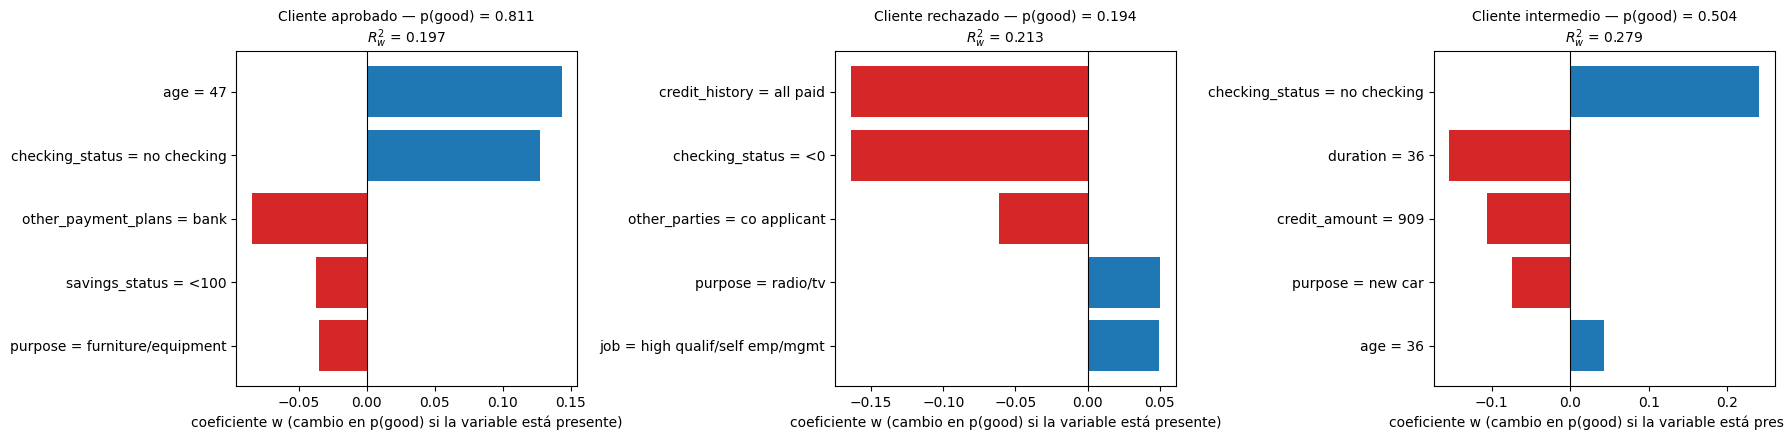

In [25]:
pos_medio = np.where((p_test >= 0.45) & (p_test <= 0.55))[0]
assert len(pos_medio) > 0, "No hay clientes de prueba con p entre 0.45 y 0.55"
POS_MEDIO = int(pos_medio[np.argmin(np.abs(p_test[pos_medio] - 0.5))])
CLIENTES = {"aprobado": POS_APROBADO, "rechazado": POS_RECHAZADO, "intermedio": POS_MEDIO}
print(f"Clientes con 0.45 <= p <= 0.55: {len(pos_medio)}")
for nombre, pos in CLIENTES.items():
    print(f"{nombre:<11s} posición {pos:3d} | índice {X_test.index[pos]:4d} | p(good) = {p_test[pos]:.4f} | y real = {y_test.iloc[pos]}")

def valor_legible(pos, col):
    return str(X_test_raw.iloc[pos][col])

LIME_RES = {}
RES["task3_1"] = {"parametros": {"N": 5000, "K": 5, "lambda": 1.0, "sigma_rel": 0.75,
                                 "intercepto_penalizado": False}, "clientes": {}}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (nombre, pos) in zip(axes, CLIENTES.items()):
    x = X_test.values[pos].astype(float)
    res = lime(x)
    LIME_RES[nombre] = res
    tabla = pd.DataFrame({"variable": [COLS[j] for j in res["top"]],
                          "valor": [valor_legible(pos, COLS[j]) for j in res["top"]],
                          "w (K=5)": res["wK"], "w (20 var.)": res["w20"][res["top"]]})
    print(f"\nCliente {nombre}: p(good) = {p_test[pos]:.4f} | intercepto = {res['bK']:.4f} | "
          f"R2_w (K=5) = {res['R2_K']:.4f} | R2_w (20 var.) = {res['R2_20']:.4f} | N_ef = {res['N_ef']:.1f}")
    display(tabla)
    RES["task3_1"]["clientes"][nombre] = {"posicion": pos, "indice": int(X_test.index[pos]), "p_good": p_test[pos],
                                          "intercepto": res["bK"], "R2_K": res["R2_K"], "R2_20": res["R2_20"],
                                          "N_ef": res["N_ef"], "tabla": tabla.to_dict(orient="records"),
                                          "w20": dict(zip(COLS, res["w20"]))}
    orden = np.argsort(np.abs(res["wK"]))
    etiquetas = [f"{COLS[res['top'][i]]} = {valor_legible(pos, COLS[res['top'][i]])}" for i in orden]
    ax.barh(etiquetas, res["wK"][orden], color=["#d62728" if v < 0 else "#1f77b4" for v in res["wK"][orden]])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Cliente {nombre} — p(good) = {p_test[pos]:.3f}\n$R^2_w$ = {res['R2_K']:.3f}", fontsize=10)
    ax.set_xlabel("coeficiente w (cambio en p(good) si la variable está presente)")
plt.tight_layout(); guardar_fig("t3_1_lime_clientes"); mostrar()

## Task 3.2 — Estabilidad de LIME en el cliente rechazado
Para cada combinación de $N\in\{500,2000,5000\}$ y $\sigma_{rel}\in\{0.5,0.75,1.5\}$ se ejecuta LIME 20 veces con semillas distintas (SEED + 0, …, SEED + 19). Se reporta el Jaccard promedio $J(A,B)=|A\cap B|/|A\cup B|$ sobre los $\binom{20}{2}=190$ pares de corridas, y el tamaño efectivo de muestra promedio $N_{ef}=(\sum_n\pi_n)^2/\sum_n\pi_n^2$.

In [26]:
x_rech = X_test.values[POS_RECHAZADO].astype(float)
CORRIDAS = 20

def estabilidad(x, N, s, corridas=CORRIDAS, K=5):
    conjuntos, nef, r2, W = [], [], [], []
    for r in range(corridas):
        res = lime(x, N=N, K=K, sigma_rel=s, seed=SEED + r)
        conjuntos.append(frozenset(int(j) for j in res["top"]))
        nef.append(res["N_ef"]); r2.append(res["R2_K"]); W.append(res["w20"])
    jac = [len(a & b) / len(a | b) for a, b in itertools.combinations(conjuntos, 2)]
    return {"jaccard": float(np.mean(jac)), "jaccard_std": float(np.std(jac)), "N_ef": float(np.mean(nef)),
            "R2_K": float(np.mean(r2)), "conjuntos": conjuntos, "W": np.array(W)}

def razon_nef_teorica(s, d=D_PRIMA):
    """E[pi]^2 / E[pi^2] con D^2 ~ Binomial(d, 0.5): fracción esperada N_ef / N."""
    s2 = (s * np.sqrt(d)) ** 2
    return (((1 + np.exp(-1 / s2)) / 2) ** d) ** 2 / (((1 + np.exp(-2 / s2)) / 2) ** d)

ESTAB = {}
t0 = time.perf_counter()
for N in [500, 2000, 5000]:
    for s in [0.5, 0.75, 1.5]:
        ESTAB[(N, s)] = estabilidad(x_rech, N, s)
print(f"Tiempo total: {time.perf_counter() - t0:.1f} s")

tabla_jac = pd.DataFrame({s: [ESTAB[(N, s)]["jaccard"] for N in [500, 2000, 5000]] for s in [0.5, 0.75, 1.5]},
                         index=[500, 2000, 5000])
tabla_jac.index.name = "N"; tabla_jac.columns.name = "sigma_rel"
tabla_nef = pd.DataFrame({s: [ESTAB[(N, s)]["N_ef"] for N in [500, 2000, 5000]] for s in [0.5, 0.75, 1.5]},
                         index=[500, 2000, 5000])
tabla_nef.index.name = "N"; tabla_nef.columns.name = "sigma_rel"
print("Jaccard promedio (190 pares de corridas):"); display(tabla_jac)
print("N_ef promedio:"); display(tabla_nef)
print("N_ef / N medido:"); display((tabla_nef.T / np.array([500, 2000, 5000])).T)
print("N_ef / N teórico, E[pi]^2 / E[pi^2] con D^2 ~ Bin(20, 0.5):",
      {s: round(razon_nef_teorica(s), 4) for s in [0.5, 0.75, 1.5]})

# Frecuencia con la que cada variable entra al top-5 en las 20 corridas (N = 5000, sigma_rel = 0.75)
frec = pd.Series(0, index=COLS, dtype=int)
for cj in ESTAB[(5000, 0.75)]["conjuntos"]:
    for j in cj: frec[COLS[j]] += 1
print("Veces en el top-5 de 20 corridas (N = 5000, sigma_rel = 0.75):")
display(frec[frec > 0].sort_values(ascending=False).to_frame("veces"))
W_ref = ESTAB[(5000, 0.75)]["W"]
tabla_w = pd.DataFrame({"|w| medio": np.abs(W_ref).mean(0), "desv. de w": W_ref.std(0, ddof=1)}, index=COLS)
tabla_w = tabla_w.sort_values("|w| medio", ascending=False)
tabla_w["rango"] = np.arange(1, len(COLS) + 1)
print("Coeficientes de las 20 corridas (N = 5000, sigma_rel = 0.75), 8 mayores:"); display(tabla_w.head(8))

RES["task3_2"] = {"jaccard": {f"N={N},s={s}": ESTAB[(N, s)]["jaccard"] for (N, s) in ESTAB},
                  "N_ef": {f"N={N},s={s}": ESTAB[(N, s)]["N_ef"] for (N, s) in ESTAB},
                  "R2_K": {f"N={N},s={s}": ESTAB[(N, s)]["R2_K"] for (N, s) in ESTAB},
                  "razon_nef_teorica": {str(s): razon_nef_teorica(s) for s in [0.5, 0.75, 1.5]},
                  "frecuencia_top5_N5000_s075": frec[frec > 0].to_dict(),
                  "coef_N5000_s075": tabla_w.head(8).to_dict(orient="index")}

Tiempo total: 1.0 s
Jaccard promedio (190 pares de corridas):


sigma_rel,0.5,0.75,1.5
N,,,
500,0.45495,0.448559,0.44718
2000,0.621992,0.624624,0.634398
5000,0.705827,0.693233,0.691729


N_ef promedio:


sigma_rel,0.5,0.75,1.5
N,,,
500,409.684,480.521,498.756
2000,1639.42,1922.5,1995.06
5000,4099.94,4806.28,4987.65


N_ef / N medido:


sigma_rel,0.5,0.75,1.5
N,,,
500,0.819369,0.961043,0.997512
2000,0.819712,0.961248,0.997531
5000,0.819989,0.961256,0.99753


N_ef / N teórico, E[pi]^2 / E[pi^2] con D^2 ~ Bin(20, 0.5): {0.5: 0.8206, 0.75: 0.9614, 1.5: 0.9975}
Veces en el top-5 de 20 corridas (N = 5000, sigma_rel = 0.75):


,veces
checking_status,20
credit_history,20
job,19
other_parties,16
purpose,13
duration,4
employment,4
other_payment_plans,3
savings_status,1


Coeficientes de las 20 corridas (N = 5000, sigma_rel = 0.75), 8 mayores:


,|w| medio,desv. de w,rango
credit_history,0.170662,0.007058,1
checking_status,0.148242,0.00663776,2
job,0.0595584,0.00646888,3
other_parties,0.0534085,0.00761446,4
purpose,0.0482841,0.00591816,5
duration,0.042447,0.0061699,6
other_payment_plans,0.0402729,0.00655855,7
employment,0.0401549,0.00566946,8


## Task 3.3 — LIME frente a SHAP
### 3.3a — Spearman entre $|w|$ (ajuste con 20 variables) y $|\phi|$ (Task 2.2), y coincidencia de las tres variables principales
LIME explica $p(\text{good})$ y SHAP el log-odds, así que se comparan rankings (Spearman), no magnitudes.

In [27]:
filas = []
for nombre, pos in CLIENTES.items():
    w20 = LIME_RES[nombre]["w20"]
    phi = PHI[pos]
    rho = spearmanr(np.abs(w20), np.abs(phi))[0]
    top3_L = [COLS[j] for j in np.argsort(-np.abs(w20), kind="stable")[:3]]
    top3_S = [COLS[j] for j in np.argsort(-np.abs(phi), kind="stable")[:3]]
    comunes = [v for v in top3_L if v in top3_S]
    filas.append({"cliente": nombre, "Spearman |w| vs |phi|": rho, "top-3 LIME": ", ".join(top3_L),
                  "top-3 SHAP": ", ".join(top3_S), "coincidencias": f"{len(comunes)}/3",
                  "comunes": ", ".join(comunes)})
tabla_33a = pd.DataFrame(filas)
display(tabla_33a)
RES["task3_3a"] = tabla_33a.to_dict(orient="records")

,cliente,Spearman |w| vs |phi|,top-3 LIME,top-3 SHAP,coincidencias,comunes
0,aprobado,0.702256,"age, checking_status, other_payment_plans","checking_status, age, other_payment_plans",3/3,"age, checking_status, other_payment_plans"
1,rechazado,0.876692,"checking_status, credit_history, other_parties","credit_history, checking_status, duration",2/3,"checking_status, credit_history"
2,intermedio,0.869173,"checking_status, duration, credit_amount","checking_status, duration, credit_amount",3/3,"checking_status, duration, credit_amount"


### 3.3b — Fidelidad $R^2_w$ según $K$
Se usan las mismas 5000 muestras (semilla 42) para todos los $K$, de modo que solo cambia el número de variables del ajuste final. El cliente pedido es el rechazado; los otros dos se agregan como referencia.

In [28]:
R2_K = {}
for nombre, pos in CLIENTES.items():
    muestras = muestras_lime(X_test.values[pos].astype(float))
    R2_K[nombre] = {K: ajustar_lime(*muestras, K=K)["R2_K"] for K in [3, 5, 10, 20]}
tabla_33b = pd.DataFrame(R2_K)
tabla_33b.index.name = "K"
display(tabla_33b)
RES["task3_3b"] = {n: {str(k): v for k, v in d.items()} for n, d in R2_K.items()}

,aprobado,rechazado,intermedio
K,,,
3,0.185837,0.19608,0.258726
5,0.197189,0.212817,0.279077
10,0.205334,0.23733,0.292002
20,0.208196,0.24355,0.294113


## Task 3.4 — Explicaciones contrafactuales del cliente rechazado
[Diap. «Explicaciones contrafactuales: qué tendría que cambiar»] Se busca el cambio más cercano y accionable que lleve al cliente a la región de aprobación.

| Parámetro | Valor |
|---|---|
| Número de candidatos | 20 000 |
| Máximo de variables cambiadas | 3 |
| Umbral $\theta$ | 0.5 |

- Inmutables: `age`, `personal_status`, `foreign_worker`.
- Accionables: `duration`, `credit_amount`, `installment_commitment`, `checking_status`, `savings_status`. Las demás variables tampoco se modifican.
- Cada candidato cambia un subconjunto aleatorio de 1 a 3 variables accionables (tamaño uniforme en {1, 2, 3}). El nuevo valor de cada una se toma al azar de los valores observados en entrenamiento, excluyendo el valor actual del cliente para que la variable realmente cambie.
- Distancia: $d(x,x')=\sum_{j\in num}\frac{|x_j-x'_j|}{MAD_j}+\sum_{j\in cat}\mathbb 1[x_j\neq x'_j]$, con MAD la desviación absoluta mediana en entrenamiento (si es 0, la desviación absoluta media).

In [29]:
INMUTABLES = ["age", "personal_status", "foreign_worker"]
ACCIONABLES = ["duration", "credit_amount", "installment_commitment", "checking_status", "savings_status"]
THETA = 0.5

def mad(col):
    v = X_train[col].values
    m = np.median(np.abs(v - np.median(v)))                 # desviación absoluta mediana
    return m if m > 0 else np.mean(np.abs(v - v.mean()))    # si es 0: desviación absoluta media
MAD = {c: mad(c) for c in NUM_COLS}
print("MAD de las variables numéricas (entrenamiento):", {c: round(v, 3) for c, v in MAD.items()})

def distancia(x, Xc):
    """d(x, x') para una matriz de candidatos Xc (n, 20)."""
    d = np.zeros(len(Xc))
    for j, c in enumerate(COLS):
        if c in NUM_COLS:
            d += np.abs(Xc[:, j] - x[j]) / MAD[c]
        else:
            d += (Xc[:, j] != x[j]).astype(float)
    return d

def generar_candidatos(x, n=20000, max_cambios=3, seed=SEED):
    rng = np.random.default_rng(seed)
    idx_acc = [COLS.index(c) for c in ACCIONABLES]
    # valores observados en entrenamiento distintos al valor actual (con su frecuencia empírica)
    opciones = {j: X_TRAIN_NP[:, j][X_TRAIN_NP[:, j] != x[j]] for j in idx_acc}
    Xc = np.tile(x, (n, 1))
    cambiadas = np.zeros((n, len(ACCIONABLES)), dtype=bool)
    for i in range(n):
        m = rng.integers(1, max_cambios + 1)                          # entre 1 y max_cambios variables
        for a in rng.choice(len(ACCIONABLES), size=m, replace=False):
            j = idx_acc[a]
            Xc[i, j] = opciones[j][rng.integers(len(opciones[j]))]
            cambiadas[i, a] = True
    return Xc, cambiadas

def decodificar(col, v):
    return str(CATEGORIAS_ORD[col][int(v)]) if col in CAT_COLS else f"{v:g}"

def buscar_contrafactuales(x, max_cambios=3, n=20000, seed=SEED, n_elegir=3):
    Xc, camb = generar_candidatos(x, n, max_cambios, seed)
    p = modelo_gb.predict_proba(pd.DataFrame(Xc, columns=COLS))[:, 1]
    validos = p >= THETA                                              # válido si p(good) >= theta
    d = distancia(x, Xc)
    elegidos, conjuntos = [], []
    for i in np.where(validos)[0][np.argsort(d[validos], kind="stable")]:
        cj = frozenset(np.array(ACCIONABLES)[camb[i]])
        if cj not in conjuntos:                                       # conjunto de variables distinto de los ya elegidos
            elegidos.append(i); conjuntos.append(cj)
        if len(elegidos) == n_elegir:
            break
    return {"Xc": Xc, "camb": camb, "p": p, "validos": validos, "d": d, "elegidos": elegidos, "max_cambios": max_cambios}

CF = buscar_contrafactuales(x_rech, max_cambios=3)
if CF["validos"].sum() == 0:
    print("Ningún candidato válido con 3 cambios: se aumenta el máximo a 5.")
    CF = buscar_contrafactuales(x_rech, max_cambios=5)
print(f"Máximo de variables cambiadas usado: {CF['max_cambios']}")

filas = []
for r, i in enumerate(CF["elegidos"], 1):
    for a in np.where(CF["camb"][i])[0]:
        c = ACCIONABLES[a]; j = COLS.index(c)
        filas.append({"contrafactual": r, "variable": c, "original": decodificar(c, x_rech[j]),
                      "nuevo": decodificar(c, CF["Xc"][i, j]), "distancia": CF["d"][i], "p(good)": CF["p"][i]})
tabla_cf = pd.DataFrame(filas)
display(tabla_cf)

v = CF["validos"]
sel = CF["elegidos"]
metricas_cf = {"validez": v.mean(), "n_validos": int(v.sum()),
               "proximidad_promedio_elegidos": CF["d"][sel].mean(),
               "dispersion_promedio_elegidos": CF["camb"][sel].sum(1).mean(),
               "proximidad_promedio_validos": CF["d"][v].mean() if v.any() else np.nan,
               "dispersion_promedio_validos": CF["camb"][v].sum(1).mean() if v.any() else np.nan,
               "max_cambios": CF["max_cambios"]}
print(f"Validez: {metricas_cf['validez']:.4f} ({metricas_cf['n_validos']} de 20000 candidatos)")
print(f"Proximidad promedio (3 elegidos): {metricas_cf['proximidad_promedio_elegidos']:.3f} | "
      f"(todos los válidos): {metricas_cf['proximidad_promedio_validos']:.3f}")
print(f"Dispersión promedio, variables cambiadas (3 elegidos): {metricas_cf['dispersion_promedio_elegidos']:.2f} | "
      f"(todos los válidos): {metricas_cf['dispersion_promedio_validos']:.2f}")
# Qué tan seguido aparece cada variable accionable entre los candidatos válidos
frec_cf = pd.Series(CF["camb"][v].mean(0) if v.any() else 0, index=ACCIONABLES)
print("Fracción de candidatos válidos que cambian cada variable:"); display(frec_cf.to_frame("fracción"))
RES["task3_4"] = {"tabla": tabla_cf.to_dict(orient="records"), "metricas": metricas_cf,
                  "MAD": MAD, "frecuencia_en_validos": frec_cf.to_dict()}

MAD de las variables numéricas (entrenamiento): {'duration': 6.0, 'credit_amount': 1057.5, 'installment_commitment': 1.0, 'residence_since': 1.0, 'age': 7.0, 'existing_credits': 0.514, 'num_dependents': 0.274}
Máximo de variables cambiadas usado: 3


,contrafactual,variable,original,nuevo,distancia,p(good)
0,1,checking_status,<0,no checking,1,0.610663
1,2,credit_amount,1940,1943,1.00284,0.610663
2,2,checking_status,<0,no checking,1.00284,0.610663
3,3,duration,18,11,1.16667,0.527437


Validez: 0.3160 (6319 de 20000 candidatos)
Proximidad promedio (3 elegidos): 1.057 | (todos los válidos): 2.807
Dispersión promedio, variables cambiadas (3 elegidos): 1.33 | (todos los válidos): 2.33
Fracción de candidatos válidos que cambian cada variable:


,fracción
duration,0.480298
credit_amount,0.339769
installment_commitment,0.349422
checking_status,0.79253
savings_status,0.365722


## Task 3.5 — Cálculos para las preguntas
### 3.5a — Relación entre $N_{ef}$ y el Jaccard, y extrapolación a $J=0.9$ con $\sigma_{rel}=0.75$
Justificación de la extrapolación: cada $w_j$ es un estimador de mínimos cuadrados ponderados, así que su error estándar decrece como $1/\sqrt{N_{ef}}$ y, por el teorema del límite central, su distribución entre corridas es aproximadamente normal. El conjunto top-5 cambia cuando el ruido hace que se crucen variables con $|w|$ parecidos cerca del 5.º lugar.

Modelo principal: con la media $\bar w_j$ y la desviación $s_j$ de las 20 corridas con $N=5000$, se simulan corridas con $w_j\sim\mathcal N(\bar w_j,\,s_j^2\cdot N_{ef}(5000)/N_{ef}(N))$ y se calcula el Jaccard esperado para cada $N$. El modelo se valida primero contra los $N=500$ y $2000$ medidos; luego se busca el menor $N$ con $J\geq0.9$ y se verifica con una corrida adicional (20 repeticiones). Si la verificación no llega a 0.9, se re-estima con los coeficientes de esa corrida (más precisos) y se verifica otra vez: con solo 20 corridas, la brecha entre el 5.º y el 6.º lugar se sobreestima cuando esas variables están casi empatadas.

Comparación: ajuste empírico $1-J\approx a\,N_{ef}^{\,b}$ en escala log-log con los tres puntos de $\sigma_{rel}=0.75$.

Validación del modelo contra los valores medidos (sigma_rel = 0.75):


,N,J medido,J modelo (desde N = 5000)
0,500,0.448559,0.45858
1,2000,0.624624,0.603726
2,5000,0.693233,0.720638


Etapa 1 — con N = 5000: brecha de |w| entre el 5.º (purpose) y el 6.º (duration) = 0.0058 ± 0.0019
Etapa 1 — N estimado para J >= 0.9: 18,500 (J modelo = 0.9073)
Verificación 1 — N = 18,500: Jaccard medido = 0.8825 | N_ef = 17,785 | 0.6 s
Etapa 2 — con N = 18,500: brecha entre el 5.º (purpose) y el 6.º (duration) = 0.0052 ± 0.0010
Etapa 2 — N estimado para J >= 0.9: 24,000 (J modelo = 0.9097)
Verificación 2 — N = 24,000: Jaccard medido = 0.9667 | N_ef = 23,072 | 0.8 s
Con N = 24,000: brecha entre el 5.º (purpose) y el 6.º (duration) = 0.0056 ± 0.0009
Referencia: con un empate exacto en el 5.º lugar el Jaccard esperado es 0.5·1 + 0.5·(4/6) = 0.833
Comparación — ley de potencias: 1 - J = 2.666 * N_ef^(-0.257) -> N ≈ 376,484


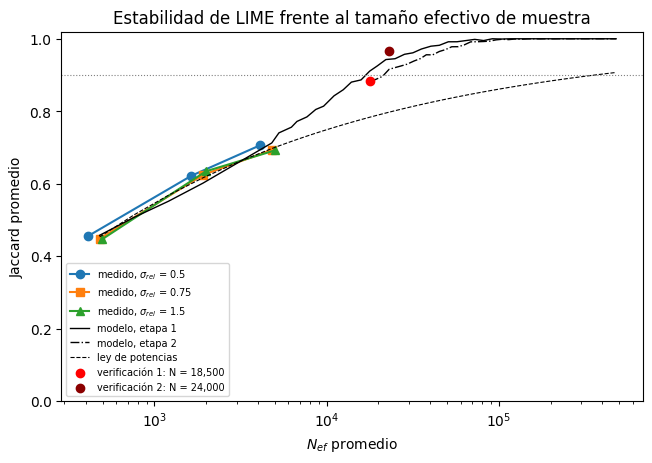

In [30]:
razon_075 = np.mean([ESTAB[(N, 0.75)]["N_ef"] / N for N in [500, 2000, 5000]])   # N_ef / N con sigma_rel = 0.75
rng_sim = np.random.default_rng(SEED)
J_OBJ, N_MAX = 0.9, 500_000

def jaccard_modelo(N, W, nef_ref, reps=100):
    """Jaccard esperado con N muestras si w_j ~ Normal(media, desv^2 * nef_ref / N_ef(N))."""
    mu, se = W.mean(0), W.std(0, ddof=1)
    escala = np.sqrt(nef_ref / (razon_075 * N))           # error estándar proporcional a 1 / sqrt(N_ef)
    J = []
    for _ in range(reps):
        Wsim = mu + rng_sim.standard_normal((CORRIDAS, D_PRIMA)) * se * escala
        cj = [frozenset(np.argsort(-np.abs(w), kind="stable")[:5].tolist()) for w in Wsim]
        J.append(np.mean([len(a & b) / len(a | b) for a, b in itertools.combinations(cj, 2)]))
    return float(np.mean(J))

def extrapolar(W, nef_ref, N_min):
    malla = np.unique(np.round(np.geomspace(N_min, N_MAX, 40) / 500).astype(int) * 500)
    Jm = np.array([jaccard_modelo(N, W, nef_ref) for N in malla])
    N_obj = int(malla[np.argmax(Jm >= J_OBJ)]) if (Jm >= J_OBJ).any() else N_MAX
    return N_obj, malla, Jm

def brecha_5_6(W):
    """Variables en 5.º y 6.º lugar por |w| medio, su brecha y el error estándar de esa brecha."""
    m = np.abs(W).mean(0); o = np.argsort(-m, kind="stable")
    se_media = W.std(0, ddof=1) / np.sqrt(len(W))
    return COLS[o[4]], COLS[o[5]], float(m[o[4]] - m[o[5]]), float(np.sqrt(se_media[o[4]] ** 2 + se_media[o[5]] ** 2))

W5, nef5 = ESTAB[(5000, 0.75)]["W"], ESTAB[(5000, 0.75)]["N_ef"]
validacion = pd.DataFrame({"N": [500, 2000, 5000],
                           "J medido": [ESTAB[(N, 0.75)]["jaccard"] for N in [500, 2000, 5000]],
                           "J modelo (desde N = 5000)": [jaccard_modelo(N, W5, nef5) for N in [500, 2000, 5000]]})
print("Validación del modelo contra los valores medidos (sigma_rel = 0.75):"); display(validacion)

# Etapa 1: extrapolación desde las 20 corridas con N = 5000
N1, malla1, J1 = extrapolar(W5, nef5, 5000)
v5, v6, g, eg = brecha_5_6(W5)
print(f"Etapa 1 — con N = 5000: brecha de |w| entre el 5.º ({v5}) y el 6.º ({v6}) = {g:.4f} ± {eg:.4f}")
print(f"Etapa 1 — N estimado para J >= {J_OBJ}: {N1:,} (J modelo = {jaccard_modelo(N1, W5, nef5):.4f})")
t0 = time.perf_counter()
verif1 = estabilidad(x_rech, N1, 0.75)
print(f"Verificación 1 — N = {N1:,}: Jaccard medido = {verif1['jaccard']:.4f} | N_ef = {verif1['N_ef']:,.0f} | {time.perf_counter() - t0:.1f} s")
VERIFS = [(N1, verif1)]
malla2 = J2 = None

# Etapa 2 (solo si no se alcanzó 0.9): re-estimar con los coeficientes, más precisos, de la verificación 1
if verif1["jaccard"] < J_OBJ and N1 < N_MAX:
    v5, v6, g, eg = brecha_5_6(verif1["W"])
    N2, malla2, J2 = extrapolar(verif1["W"], verif1["N_ef"], N1)
    print(f"Etapa 2 — con N = {N1:,}: brecha entre el 5.º ({v5}) y el 6.º ({v6}) = {g:.4f} ± {eg:.4f}")
    print(f"Etapa 2 — N estimado para J >= {J_OBJ}: {N2:,} (J modelo = {jaccard_modelo(N2, verif1['W'], verif1['N_ef']):.4f})")
    t0 = time.perf_counter()
    verif2 = estabilidad(x_rech, N2, 0.75)
    print(f"Verificación 2 — N = {N2:,}: Jaccard medido = {verif2['jaccard']:.4f} | N_ef = {verif2['N_ef']:,.0f} | {time.perf_counter() - t0:.1f} s")
    v5, v6, g, eg = brecha_5_6(verif2["W"])
    print(f"Con N = {N2:,}: brecha entre el 5.º ({v5}) y el 6.º ({v6}) = {g:.4f} ± {eg:.4f}")
    VERIFS.append((N2, verif2))

# Referencia: con un empate exacto en el 5.º lugar, 4 variables son fijas y la 5.ª sale al azar entre 2
print(f"Referencia: con un empate exacto en el 5.º lugar el Jaccard esperado es 0.5·1 + 0.5·(4/6) = {0.5 + 0.5 * 4 / 6:.3f}")

def ajuste_loglog(puntos):
    nef = np.array([p[0] for p in puntos]); J = np.array([p[1] for p in puntos])
    b, log_a = np.polyfit(np.log(nef), np.log(np.clip(1 - J, 1e-3, None)), 1)
    return np.exp(log_a), b
a075, b075 = ajuste_loglog([(ESTAB[(N, 0.75)]["N_ef"], ESTAB[(N, 0.75)]["jaccard"]) for N in [500, 2000, 5000]])
N_pot = ((1 - J_OBJ) / a075) ** (1 / b075) / razon_075 if b075 < 0 else np.inf
print(f"Comparación — ley de potencias: 1 - J = {a075:.3f} * N_ef^({b075:.3f}) -> N ≈ {N_pot:,.0f}")

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for s_, m in zip([0.5, 0.75, 1.5], ["o", "s", "^"]):
    ax.plot([ESTAB[(N, s_)]["N_ef"] for N in [500, 2000, 5000]],
            [ESTAB[(N, s_)]["jaccard"] for N in [500, 2000, 5000]], marker=m, label=f"medido, $\\sigma_{{rel}}$ = {s_}")
N_curva = np.unique(np.r_[np.geomspace(500, 5000, 6).round(), malla1])
ax.plot(razon_075 * N_curva, [jaccard_modelo(N, W5, nef5, reps=40) for N in N_curva], "k-", lw=1, label="modelo, etapa 1")
if malla2 is not None:
    ax.plot(razon_075 * malla2, J2, "k-.", lw=1, label="modelo, etapa 2")
ax.plot(razon_075 * N_curva, 1 - a075 * (razon_075 * N_curva) ** b075, "k--", lw=0.8, label="ley de potencias")
for i, (Nv, vv) in enumerate(VERIFS, 1):
    ax.scatter([vv["N_ef"]], [vv["jaccard"]], color=["red", "darkred"][i - 1], zorder=5, label=f"verificación {i}: N = {Nv:,}")
ax.axhline(J_OBJ, color="gray", lw=0.8, ls=":")
ax.set_xscale("log"); ax.set_xlabel("$N_{ef}$ promedio"); ax.set_ylabel("Jaccard promedio"); ax.set_ylim(0, 1.02)
ax.legend(fontsize=7); ax.set_title("Estabilidad de LIME frente al tamaño efectivo de muestra")
guardar_fig("t3_5a_jaccard_vs_nef"); mostrar()
RES["task3_5a"] = {"razon_nef_075": razon_075, "validacion_modelo": validacion.to_dict(orient="records"),
                   "verificaciones": [{"N": Nv, "jaccard": vv["jaccard"], "N_ef": vv["N_ef"],
                                       "brecha_5_6": brecha_5_6(vv["W"])} for Nv, vv in VERIFS],
                   "brecha_5_6_N5000": brecha_5_6(W5),
                   "ley_potencias": {"a": a075, "b": b075, "N_estimado": N_pot}}

### 3.5b — Cliente y variable donde LIME y SHAP discrepan más
Para comparar escalas distintas (LIME en probabilidad, SHAP en log-odds), cada vector se normaliza por su suma de valores absolutos: $s_j = w_j/\sum_k|w_k|$ y $s_j=\phi_j/\sum_k|\phi_k|$. La discrepancia es $|s^{LIME}_j-s^{SHAP}_j|$ (tiene en cuenta signo y magnitud).

Pruebas de la hipótesis:
1. Localidad: LIME con $\sigma_{rel}\in\{0.25,0.5,0.75,1.0,1.5\}$ (5 semillas cada uno).
2. Escala de salida: SHAP intervencional sobre la probabilidad, con el mismo fondo.
3. Interacción: aporte marginal promedio $\Delta_j(s)=E[f(x_{S\cup j},r)-f(x_S,r)]$ según el tamaño $s=|S|$ de la coalición. Shapley promedia $\Delta_j(s)$ con el mismo peso para cada $s$; si $\Delta_j(s)$ cambia mucho con $s$, el efecto de la variable depende de qué otras están presentes.
4. No linealidad: $p(\text{good})$ y log-odds del cliente al variar solo esa variable, junto con el efecto promedio sobre el fondo (dependencia parcial).

,cliente,variable,valor,w LIME,phi SHAP,s LIME,s SHAP,discrepancia,rango LIME,rango SHAP
1,aprobado,duration,18,0.0114124,-0.20813,0.0192857,-0.0555276,0.0748133,12,5
41,intermedio,duration,36,-0.154684,-1.35432,-0.184174,-0.249029,0.0648557,2,2
21,rechazado,duration,18,-0.0325679,-0.394438,-0.0420143,-0.0906714,0.048657,10,3
3,aprobado,purpose,furniture/equipment,-0.0364057,-0.35838,-0.0615218,-0.0956135,0.0340917,5,4
53,intermedio,other_payment_plans,none,0.0398594,0.104073,0.0474583,0.0191367,0.0283217,6,10
34,rechazado,housing,for free,-0.0418348,-0.125373,-0.0539692,-0.0288202,0.025149,7,10
43,intermedio,purpose,new car,-0.0734143,-0.607344,-0.0874103,-0.111677,0.0242669,4,4
2,aprobado,credit_history,existing paid,-0.000999728,-0.086237,-0.00168944,-0.0230075,0.021318,19,9


Mayor discrepancia: cliente aprobado, variable duration = 18

Prueba 1 — localidad:


,sigma_rel,s LIME (media),s LIME (desv.),s SHAP,discrepancia
0,0.25,0.00207292,0.0250741,-0.0555276,0.0576005
1,0.5,0.00477032,0.0122987,-0.0555276,0.0602979
2,0.75,0.00549733,0.0120814,-0.0555276,0.061025
3,1,0.0057824,0.0121176,-0.0555276,0.06131
4,1.5,0.00599587,0.0121846,-0.0555276,0.0615235



Prueba 2 — SHAP en probabilidad: phi = -0.0111 | s = -0.0220 (log-odds: s = -0.0555; LIME sigma_rel = 0.75: s = +0.0193)

Prueba 3 — promedio de Delta_j(s) sobre s (≈ phi SHAP): -0.1996 (phi del Task 2.2: -0.2081)
Delta log-odds: mín -0.3245 (s=2) | máx -0.0644 (s=15)


,s,Delta log-odds,Delta prob
0,0,-0.255258,-0.0110849
4,4,-0.224534,-0.0240935
9,9,-0.144926,-0.0134789
14,14,-0.189113,-0.0108842
19,19,-0.115443,0.0115083


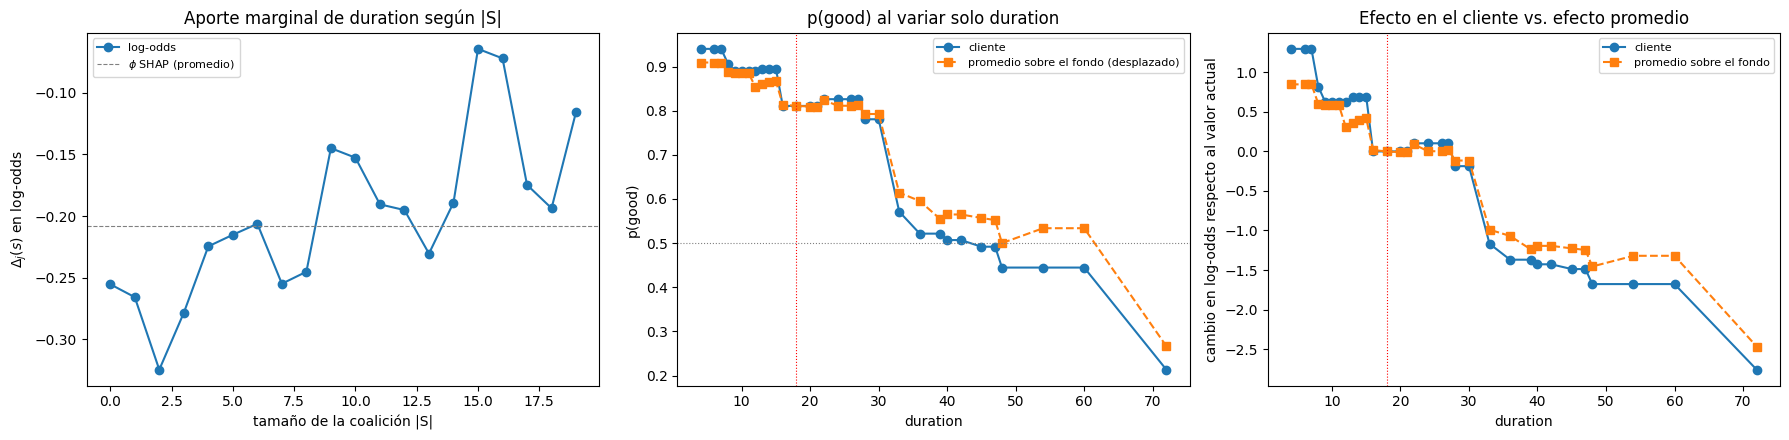

In [31]:
filas = []
for nombre, pos in CLIENTES.items():
    w = LIME_RES[nombre]["w20"]; phi = PHI[pos]
    sL, sS = w / np.abs(w).sum(), phi / np.abs(phi).sum()
    rL = pd.Series(-np.abs(w)).rank(method="min").values; rS = pd.Series(-np.abs(phi)).rank(method="min").values
    for j, c in enumerate(COLS):
        filas.append({"cliente": nombre, "variable": c, "valor": valor_legible(pos, c), "w LIME": w[j],
                      "phi SHAP": phi[j], "s LIME": sL[j], "s SHAP": sS[j], "discrepancia": abs(sL[j] - sS[j]),
                      "rango LIME": int(rL[j]), "rango SHAP": int(rS[j])})
tabla_disc = pd.DataFrame(filas).sort_values("discrepancia", ascending=False)
display(tabla_disc.head(8))
CLI_D, VAR_D = tabla_disc.iloc[0]["cliente"], tabla_disc.iloc[0]["variable"]
POS_D, J_D = CLIENTES[CLI_D], COLS.index(VAR_D)
x_D = X_test.values[POS_D].astype(float)
s_shap_D = tabla_disc.iloc[0]["s SHAP"]
print(f"Mayor discrepancia: cliente {CLI_D}, variable {VAR_D} = {valor_legible(POS_D, VAR_D)}")

# Prueba 1: localidad (sigma_rel)
filas_s = []
for s in [0.25, 0.5, 0.75, 1.0, 1.5]:
    sh = []
    for r in range(5):
        w = lime(x_D, sigma_rel=s, seed=SEED + r)["w20"]
        sh.append(w[J_D] / np.abs(w).sum())
    filas_s.append({"sigma_rel": s, "s LIME (media)": np.mean(sh), "s LIME (desv.)": np.std(sh),
                    "s SHAP": s_shap_D, "discrepancia": abs(np.mean(sh) - s_shap_D)})
tabla_sigma = pd.DataFrame(filas_s)
print("\nPrueba 1 — localidad:"); display(tabla_sigma)

# Prueba 2: SHAP intervencional en probabilidad
exp_prob = shap.TreeExplainer(modelo_gb, data=fondo, feature_perturbation="interventional", model_output="probability")
phi_prob = exp_prob.shap_values(X_test.iloc[[POS_D]])[0]
s_shap_prob = phi_prob[J_D] / np.abs(phi_prob).sum()
print(f"\nPrueba 2 — SHAP en probabilidad: phi = {phi_prob[J_D]:+.4f} | s = {s_shap_prob:+.4f} "
      f"(log-odds: s = {s_shap_D:+.4f}; LIME sigma_rel = 0.75: s = {tabla_disc.iloc[0]['s LIME']:+.4f})")

# Prueba 3: aporte marginal según el tamaño de la coalición
rng_c = np.random.default_rng(SEED)
otros = [k for k in range(D_PRIMA) if k != J_D]
filas_c = []
for s in range(D_PRIMA):
    n_m = 300
    con, sin = [], []
    for _ in range(n_m):
        S = rng_c.choice(otros, size=s, replace=False)
        r = fondo.values[rng_c.integers(len(fondo))].astype(float)
        z = r.copy(); z[S] = x_D[S]                    # x_S y el resto del fondo
        sin.append(z.copy()); z[J_D] = x_D[J_D]; con.append(z)
    f_con = modelo_gb.decision_function(pd.DataFrame(np.array(con), columns=COLS))
    f_sin = modelo_gb.decision_function(pd.DataFrame(np.array(sin), columns=COLS))
    filas_c.append({"s": s, "Delta log-odds": (f_con - f_sin).mean(), "Delta prob": (sig(f_con) - sig(f_sin)).mean()})
tabla_coal = pd.DataFrame(filas_c)
print(f"\nPrueba 3 — promedio de Delta_j(s) sobre s (≈ phi SHAP): {tabla_coal['Delta log-odds'].mean():+.4f} "
      f"(phi del Task 2.2: {PHI[POS_D, J_D]:+.4f})")
print(f"Delta log-odds: mín {tabla_coal['Delta log-odds'].min():+.4f} (s={int(tabla_coal.loc[tabla_coal['Delta log-odds'].idxmin(), 's'])}) | "
      f"máx {tabla_coal['Delta log-odds'].max():+.4f} (s={int(tabla_coal.loc[tabla_coal['Delta log-odds'].idxmax(), 's'])})")
display(tabla_coal.iloc[[0, 4, 9, 14, 19]])

# Prueba 4: variar solo esa variable en el cliente
vals = np.unique(X_TRAIN_NP[:, J_D])
if len(vals) > 60:
    vals = np.unique(np.quantile(X_TRAIN_NP[:, J_D], np.linspace(0, 1, 61)))
Xv = np.tile(x_D, (len(vals), 1)); Xv[:, J_D] = vals
f_cli = modelo_gb.decision_function(pd.DataFrame(Xv, columns=COLS))
pd_f = []
for v_ in vals:
    Fb = fondo.values.astype(float).copy(); Fb[:, J_D] = v_
    pd_f.append(modelo_gb.decision_function(pd.DataFrame(Fb, columns=COLS)).mean())
pd_f = np.array(pd_f)
i0 = int(np.argmin(np.abs(vals - x_D[J_D])))
etq = [decodificar(VAR_D, v_) for v_ in vals]
xpos = np.arange(len(vals)) if VAR_D in CAT_COLS else vals

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(tabla_coal["s"], tabla_coal["Delta log-odds"], "o-", label="log-odds")
axes[0].axhline(PHI[POS_D, J_D], color="gray", ls="--", lw=0.8, label="$\\phi$ SHAP (promedio)")
axes[0].set_xlabel("tamaño de la coalición |S|"); axes[0].set_ylabel("$\\Delta_j(s)$ en log-odds")
axes[0].set_title(f"Aporte marginal de {VAR_D} según |S|"); axes[0].legend(fontsize=8)
axes[1].plot(xpos, sig(f_cli), "o-", label="cliente")
axes[1].plot(xpos, sig(pd_f - pd_f[i0] + f_cli[i0]), "s--", label="promedio sobre el fondo (desplazado)")
axes[1].axhline(THETA, color="gray", lw=0.8, ls=":")
axes[1].set_ylabel("p(good)"); axes[1].set_title(f"p(good) al variar solo {VAR_D}")
axes[2].plot(xpos, f_cli - f_cli[i0], "o-", label="cliente")
axes[2].plot(xpos, pd_f - pd_f[i0], "s--", label="promedio sobre el fondo")
axes[2].set_ylabel("cambio en log-odds respecto al valor actual"); axes[2].set_title("Efecto en el cliente vs. efecto promedio")
for ax in axes[1:]:
    ax.axvline(xpos[i0], color="red", lw=0.8, ls=":")
    if VAR_D in CAT_COLS:
        ax.set_xticks(xpos); ax.set_xticklabels(etq, rotation=30, ha="right", fontsize=8)
    ax.set_xlabel(VAR_D); ax.legend(fontsize=8)
plt.tight_layout(); guardar_fig("t3_5b_discrepancia"); mostrar()
RES["task3_5b"] = {"cliente": CLI_D, "variable": VAR_D, "valor": valor_legible(POS_D, VAR_D),
                   "top_discrepancias": tabla_disc.head(8).to_dict(orient="records"),
                   "prueba_sigma": tabla_sigma.to_dict(orient="records"),
                   "shap_prob_phi": phi_prob[J_D], "shap_prob_s": s_shap_prob,
                   "coaliciones": tabla_coal.to_dict(orient="records"),
                   "curva_valores": etq, "curva_p_cliente": sig(f_cli), "curva_logodds_cliente": f_cli,
                   "curva_logodds_promedio": pd_f}

### 3.5d — Variables de los contrafactuales frente a las tres de mayor $|\phi|$ del cliente rechazado
Para cada variable del top-3 de $|\phi|$ se indica si es inmutable, accionable o no accionable, y se mide el mejor resultado posible cambiando solo esa variable: la mayor $p(\text{good})$ alcanzable, la distancia mínima para llegar a $\theta$ y el aumento de probabilidad por unidad de distancia.

In [32]:
top3_phi = [COLS[j] for j in np.argsort(-np.abs(PHI[POS_RECHAZADO]), kind="stable")[:3]]
vars_cf = sorted({str(c) for i in CF["elegidos"] for c in np.array(ACCIONABLES)[CF["camb"][i]]})
print("Top-3 |phi| del rechazado:", top3_phi, "| variables cambiadas en los contrafactuales:", vars_cf)
p_x = p_test[POS_RECHAZADO]

def barrido_una_variable(c):
    j = COLS.index(c)
    vals = np.unique(X_TRAIN_NP[:, j]); vals = vals[vals != x_rech[j]]
    Xv = np.tile(x_rech, (len(vals), 1)); Xv[:, j] = vals
    p = modelo_gb.predict_proba(pd.DataFrame(Xv, columns=COLS))[:, 1]
    d = distancia(x_rech, Xv)
    ok = p >= THETA
    return {"variable": c, "tipo": "inmutable" if c in INMUTABLES else ("accionable" if c in ACCIONABLES else "no accionable"),
            "phi": PHI[POS_RECHAZADO, j], "valor actual": decodificar(c, x_rech[j]),
            "mejor p sola": p.max(), "valor de mejor p": decodificar(c, vals[p.argmax()]),
            "dist. mínima a theta (sola)": d[ok].min() if ok.any() else np.nan,
            "máx. aumento de p por unidad de distancia": ((p - p_x) / d).max(),
            "en contrafactuales": c in vars_cf}
tabla_35d = pd.DataFrame([barrido_una_variable(c) for c in dict.fromkeys(top3_phi + ACCIONABLES)])
display(tabla_35d)
RES["task3_5d"] = {"top3_phi": top3_phi, "vars_contrafactuales": vars_cf, "tabla": tabla_35d.to_dict(orient="records")}

Top-3 |phi| del rechazado: ['credit_history', 'checking_status', 'duration'] | variables cambiadas en los contrafactuales: ['checking_status', 'credit_amount', 'duration']


,variable,tipo,phi,valor actual,mejor p sola,valor de mejor p,dist. mínima a theta (sola),máx. aumento de p por unidad de distancia,en contrafactuales
0,credit_history,no accionable,-0.937873,all paid,0.527032,critical/other existing credit,1,0.332594,False
1,checking_status,accionable,-0.837452,<0,0.610663,no checking,1,0.416225,True
2,duration,accionable,-0.394438,18,0.548915,4,1.16667,0.487011,True
3,credit_amount,accionable,-0.042284,1940,0.51167,392,1.46383,0.221015,True
4,installment_commitment,accionable,-0.0738625,3,0.207147,2,NaN,0.0127087,False
5,savings_status,accionable,-0.16966,<100,0.327279,no known savings,NaN,0.132841,False


---
# Task 4 — Validación de las explicaciones
## Task 4.1 — Deletion e insertion para el Grad-CAM del Task 1.2
[Diap. «Desconfiar de las explicaciones: validar lo que nos cuentan», panel B] Si el mapa es fiel, quitar primero los píxeles que marca como importantes debe bajar rápido la probabilidad (AUC de deletion bajo) y agregarlos primero debe subirla rápido (AUC de insertion alto), comparado con un orden aleatorio.

- Clase: la de mayor probabilidad de cada imagen. Mapa: Grad-CAM de 224 × 224 del Task 1.2.
- $P=20$ pasos; en el paso $k$ se modifica la fracción $k/P$ de los píxeles más importantes (los 3 canales de cada píxel).
- Deletion: se reemplazan por gris medio (0.5 por canal, antes de normalizar). Insertion: se parte de la imagen desenfocada (gaussiano, $\sigma=10$ px, kernel de 61 px) y se insertan los píxeles originales.
- $\text{AUC}=\frac1P\sum_{k=1}^{P}c_k$, con $c_k$ la probabilidad de la clase en el paso $k$.
- 10 órdenes aleatorios de píxeles (semilla 42), los mismos para las tres imágenes y para ambas métricas.

Tiempo: 13.4 s


,0,1,2
imagen,a,b,c
clase,banana,Egyptian cat,ox
p original,0.996814,0.232877,0.421027
p desenfocada,0.0222232,0.00132946,0.000512404
AUC_del mapa,0.14926,0.000238477,0.00343568
AUC_del azar (media),0.0364281,0.000664829,0.0162207
AUC_del azar (desv.),0.00787643,0.000519977,0.00390948
dif. del (mapa - azar),0.112832,-0.000426352,-0.012785
z del,14.3253,-0.819944,-3.27026
AUC_ins mapa,0.771226,0.227484,0.38445


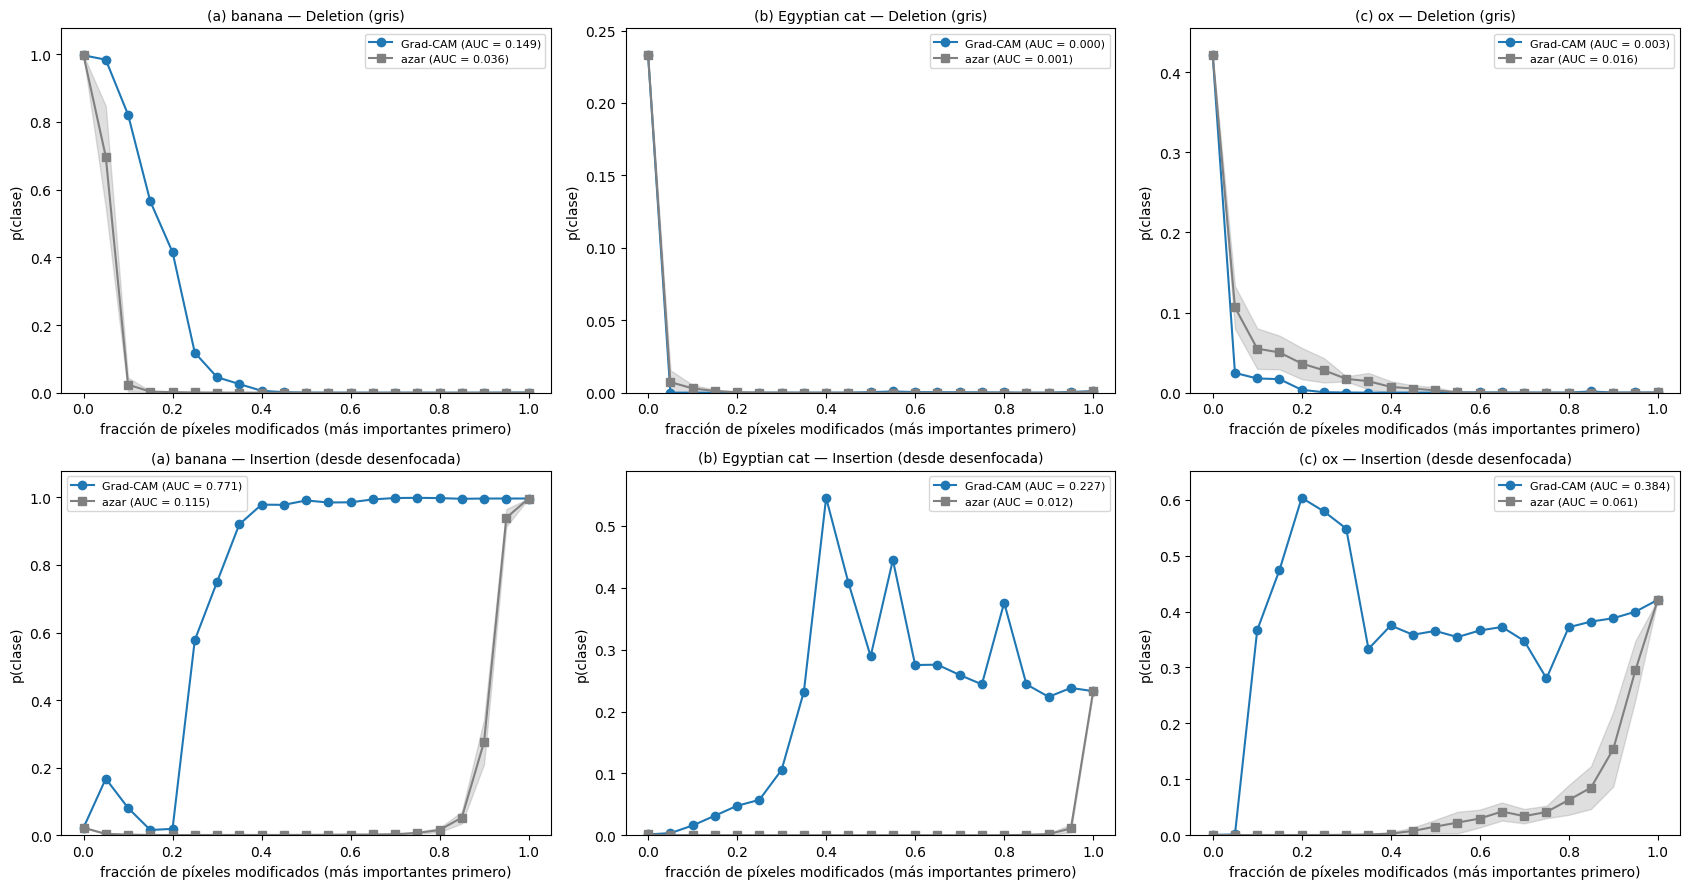

In [33]:
import torchvision.transforms.functional as TF

P_PASOS, N_ORDENES, NPIX = 20, 10, 224 * 224

def probs_clase(imgs, c, red=None, lote=20):
    """p(c) para un lote de imágenes (B, 224, 224, 3) en [0, 1]."""
    red = modelo if red is None else red
    salida = []
    with torch.no_grad():
        for i in range(0, len(imgs), lote):
            x = torch.from_numpy(np.ascontiguousarray(imgs[i:i + lote])).permute(0, 3, 1, 2).float()
            x = transforms.functional.normalize(x, MEDIA, DESV)
            salida.append(red(x).softmax(dim=1)[:, c])
    return torch.cat(salida).numpy()

def desenfocar(img, sigma=10.0):
    t = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1)
    k = int(2 * round(3 * sigma) + 1)                                 # kernel de 6 sigma + 1 = 61 px
    return TF.gaussian_blur(t, kernel_size=[k, k], sigma=[sigma, sigma]).permute(1, 2, 0).numpy()

GRIS_IMG = np.full((224, 224, 3), 0.5, dtype=np.float32)

def curva(img, ref, orden, c, modo):
    """c_k, k = 1..P. modo 'del': img -> ref en los píxeles de 'orden'; 'ins': ref -> img."""
    fi, fr = img.reshape(-1, 3), ref.reshape(-1, 3)
    lote = []
    for k in range(1, P_PASOS + 1):
        idx = orden[:int(round(k * NPIX / P_PASOS))]                 # fracción k/P de los píxeles
        out = (fi if modo == "del" else fr).copy()
        out[idx] = (fr if modo == "del" else fi)[idx]
        lote.append(out.reshape(224, 224, 3))
    return probs_clase(np.stack(lote), c)

rng_ord = np.random.default_rng(SEED)
ORDENES_AZAR = [rng_ord.permutation(NPIX) for _ in range(N_ORDENES)]
ORDEN_MAPA = {k: np.argsort(-GC[k]["L_224"].numpy().ravel(), kind="stable") for k in IMAGENES}
BORROSA = {k: desenfocar(IMG[k]) for k in IMAGENES}

CURVAS, filas = {}, []
t0 = time.perf_counter()
for k in IMAGENES:
    c = TOP1[k]
    p0 = probs_clase(IMG[k][None], c)[0]; pb = probs_clase(BORROSA[k][None], c)[0]
    del_m = curva(IMG[k], GRIS_IMG, ORDEN_MAPA[k], c, "del")
    ins_m = curva(IMG[k], BORROSA[k], ORDEN_MAPA[k], c, "ins")
    del_r = np.array([curva(IMG[k], GRIS_IMG, o, c, "del") for o in ORDENES_AZAR])
    ins_r = np.array([curva(IMG[k], BORROSA[k], o, c, "ins") for o in ORDENES_AZAR])
    CURVAS[k] = {"p0": p0, "p_borrosa": pb, "del_m": del_m, "ins_m": ins_m, "del_r": del_r, "ins_r": ins_r}
    auc_dr, auc_ir = del_r.mean(1), ins_r.mean(1)
    filas.append({"imagen": k, "clase": CATEGORIAS[c], "p original": p0, "p desenfocada": pb,
                  "AUC_del mapa": del_m.mean(), "AUC_del azar (media)": auc_dr.mean(), "AUC_del azar (desv.)": auc_dr.std(),
                  "dif. del (mapa - azar)": del_m.mean() - auc_dr.mean(),
                  "z del": (del_m.mean() - auc_dr.mean()) / auc_dr.std(),
                  "AUC_ins mapa": ins_m.mean(), "AUC_ins azar (media)": auc_ir.mean(), "AUC_ins azar (desv.)": auc_ir.std(),
                  "dif. ins (mapa - azar)": ins_m.mean() - auc_ir.mean(),
                  "z ins": (ins_m.mean() - auc_ir.mean()) / auc_ir.std()})
print(f"Tiempo: {time.perf_counter() - t0:.1f} s")
tabla_41 = pd.DataFrame(filas)
display(tabla_41.T)
RES["task4_1"] = {"tabla": tabla_41.to_dict(orient="records"),
                  "curvas": {k: {kk: vv for kk, vv in v.items()} for k, v in CURVAS.items()}}

fracs = np.arange(0, P_PASOS + 1) / P_PASOS
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for col, k in enumerate(IMAGENES):
    cv = CURVAS[k]
    for fila, (modo, c0, titulo) in enumerate([("del", cv["p0"], "Deletion (gris)"), ("ins", cv["p_borrosa"], "Insertion (desde desenfocada)")]):
        ax = axes[fila, col]
        m = np.r_[c0, cv[f"{modo}_m"]]; r = np.c_[np.full(N_ORDENES, c0), cv[f"{modo}_r"]]
        ax.plot(fracs, m, "o-", color="#1f77b4", label=f"Grad-CAM (AUC = {cv[f'{modo}_m'].mean():.3f})")
        ax.plot(fracs, r.mean(0), "s-", color="gray", label=f"azar (AUC = {cv[f'{modo}_r'].mean():.3f})")
        ax.fill_between(fracs, r.mean(0) - r.std(0), r.mean(0) + r.std(0), color="gray", alpha=0.25)
        ax.set_title(f"({k}) {CATEGORIAS[TOP1[k]]} — {titulo}", fontsize=10)
        ax.set_xlabel("fracción de píxeles modificados (más importantes primero)"); ax.set_ylabel("p(clase)")
        ax.set_ylim(0, max(m.max(), (r.mean(0) + r.std(0)).max()) * 1.08); ax.legend(fontsize=8)
plt.tight_layout(); guardar_fig("t4_1_deletion_insertion"); mostrar()

### 4.3a (cálculos) — Forma de las curvas y referencia desenfocada en deletion
- Celdas del mapa: cuántas de las 49 celdas de 32 × 32 px contienen píxeles ya quitados en cada paso (el mapa viene de una rejilla de 7 × 7).
- Deletion en la imagen (a) con la imagen desenfocada como referencia en lugar de gris (también se calcula para (b) y (c) como referencia).

Celdas de 7 × 7 tocadas en cada paso (pasos 1, 2, 3, 4, 5, 10, 20):
  (a): [7, 10, 15, 16, 19, 32, 49]
  (b): [5, 9, 12, 13, 18, 34, 49]
  (c): [4, 9, 14, 17, 19, 34, 49]


,imagen,AUC_del mapa (gris),AUC_del mapa (desenfocada),AUC_del azar gris (media ± desv.),AUC_del azar desenfocada (media ± desv.),z desenfocada
0,a,0.14926,0.30154,0.0364 ± 0.0079,0.0670 ± 0.0115,20.4391
1,b,0.000238477,0.000160176,0.0007 ± 0.0005,0.0005 ± 0.0003,-1.23966
2,c,0.00343568,0.0126231,0.0162 ± 0.0039,0.0432 ± 0.0136,-2.24235


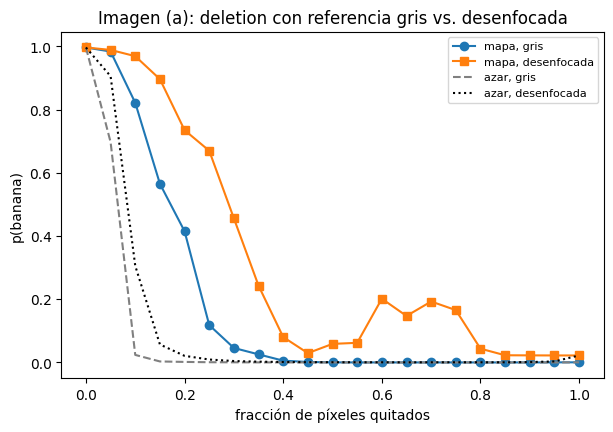

In [34]:
celdas = {}
for k in IMAGENES:
    cel = []
    for paso in range(1, P_PASOS + 1):
        idx = ORDEN_MAPA[k][:int(round(paso * NPIX / P_PASOS))]
        cel.append(len(np.unique((idx // 224) // 32 * 7 + (idx % 224) // 32)))
    celdas[k] = cel
print("Celdas de 7 × 7 tocadas en cada paso (pasos 1, 2, 3, 4, 5, 10, 20):")
for k in IMAGENES:
    print(f"  ({k}):", [celdas[k][i] for i in [0, 1, 2, 3, 4, 9, 19]])

filas = []
CURVAS_BLUR = {}
for k in IMAGENES:
    c = TOP1[k]
    del_m_b = curva(IMG[k], BORROSA[k], ORDEN_MAPA[k], c, "del")
    del_r_b = np.array([curva(IMG[k], BORROSA[k], o, c, "del") for o in ORDENES_AZAR])
    CURVAS_BLUR[k] = {"del_m": del_m_b, "del_r": del_r_b}
    filas.append({"imagen": k, "AUC_del mapa (gris)": CURVAS[k]["del_m"].mean(),
                  "AUC_del mapa (desenfocada)": del_m_b.mean(),
                  "AUC_del azar gris (media ± desv.)": f"{CURVAS[k]['del_r'].mean(1).mean():.4f} ± {CURVAS[k]['del_r'].mean(1).std():.4f}",
                  "AUC_del azar desenfocada (media ± desv.)": f"{del_r_b.mean(1).mean():.4f} ± {del_r_b.mean(1).std():.4f}",
                  "z desenfocada": (del_m_b.mean() - del_r_b.mean(1).mean()) / del_r_b.mean(1).std()})
tabla_43a = pd.DataFrame(filas)
display(tabla_43a)

fig, ax = plt.subplots(figsize=(7, 4.5))
cv = CURVAS["a"]
ax.plot(fracs, np.r_[cv["p0"], cv["del_m"]], "o-", label="mapa, gris")
ax.plot(fracs, np.r_[cv["p0"], CURVAS_BLUR["a"]["del_m"]], "s-", label="mapa, desenfocada")
ax.plot(fracs, np.r_[cv["p0"], cv["del_r"].mean(0)], "--", color="gray", label="azar, gris")
ax.plot(fracs, np.r_[cv["p0"], CURVAS_BLUR["a"]["del_r"].mean(0)], ":", color="black", label="azar, desenfocada")
ax.set_xlabel("fracción de píxeles quitados"); ax.set_ylabel(f"p({CATEGORIAS[TOP1['a']]})")
ax.set_title("Imagen (a): deletion con referencia gris vs. desenfocada"); ax.legend(fontsize=8)
guardar_fig("t4_3a_deletion_gris_vs_desenfocada"); mostrar()
RES["task4_3a"] = {"celdas_tocadas": celdas, "tabla": tabla_43a.to_dict(orient="records"),
                   "curvas_desenfocada": CURVAS_BLUR}

## Task 4.2 — Prueba de aleatorización de parámetros en cascada
[Diap. «Desconfiar de las explicaciones», panel A] Si el mapa depende del modelo, debe cambiar a medida que se destruyen los pesos aprendidos.

Etapas acumulativas sobre una copia del modelo: `fc` → + `layer4` → + `layer3` → + `layer2` → + `layer1` → + `conv1`. En cada etapa se llama `reset_parameters()` de todos los módulos del bloque (inicialización por defecto de PyTorch: Kaiming uniforme en `Conv2d`/`Linear`; peso 1, sesgo 0 y estadísticas 0/1 en `BatchNorm2d`). En la última etapa solo se reinicia `conv1`; `bn1` conserva sus pesos, como pide el enunciado. Semilla: `torch.manual_seed(42)` antes de la cascada.

En cada etapa se calcula el Grad-CAM de 7 × 7 (con ReLU) para la clase de mayor probabilidad en el modelo original y su correlación de Spearman con el mapa original. Como referencia extra se reporta el Spearman de los mapas sin ReLU, que no tiene empates en 0.

Spearman entre el Grad-CAM 7 × 7 de cada etapa y el original:


,(a) banana,(b) Egyptian cat,(c) ox
etapa,,,
fc,0.810816,-0.382984,0.793093
+ layer4,-0.346005,0.243014,-0.163785
+ layer3,0.160016,0.225161,0.0870598
+ layer2,0.012551,-0.140333,-0.19166
+ layer1,0.244032,-0.192584,-0.160768
+ conv1,0.229082,0.0500605,0.212227


Extra — Spearman sin ReLU:


,a,b,c
etapa,,,
fc,0.810816,-0.628571,0.775102
layer4,-0.342551,0.237959,-0.167959
layer3,0.158061,0.197653,0.0673469
layer2,0.012551,-0.150612,-0.144796
layer1,0.26051,-0.17,-0.228776
conv1,0.229082,0.0396939,0.235918


Extra — nueva clase top-1 del modelo aleatorizado:


,a,b,c
etapa,,,
fc,fountain pen,shield,mushroom
layer4,barracouta,brambling,barracouta
layer3,colobus,barracouta,barracouta
layer2,colobus,colobus,colobus
layer1,colobus,colobus,colobus
conv1,colobus,colobus,colobus


Primera etapa con Spearman < 0.3 (o mapa constante): {'a': '+ layer4', 'b': 'fc', 'c': '+ layer4'}


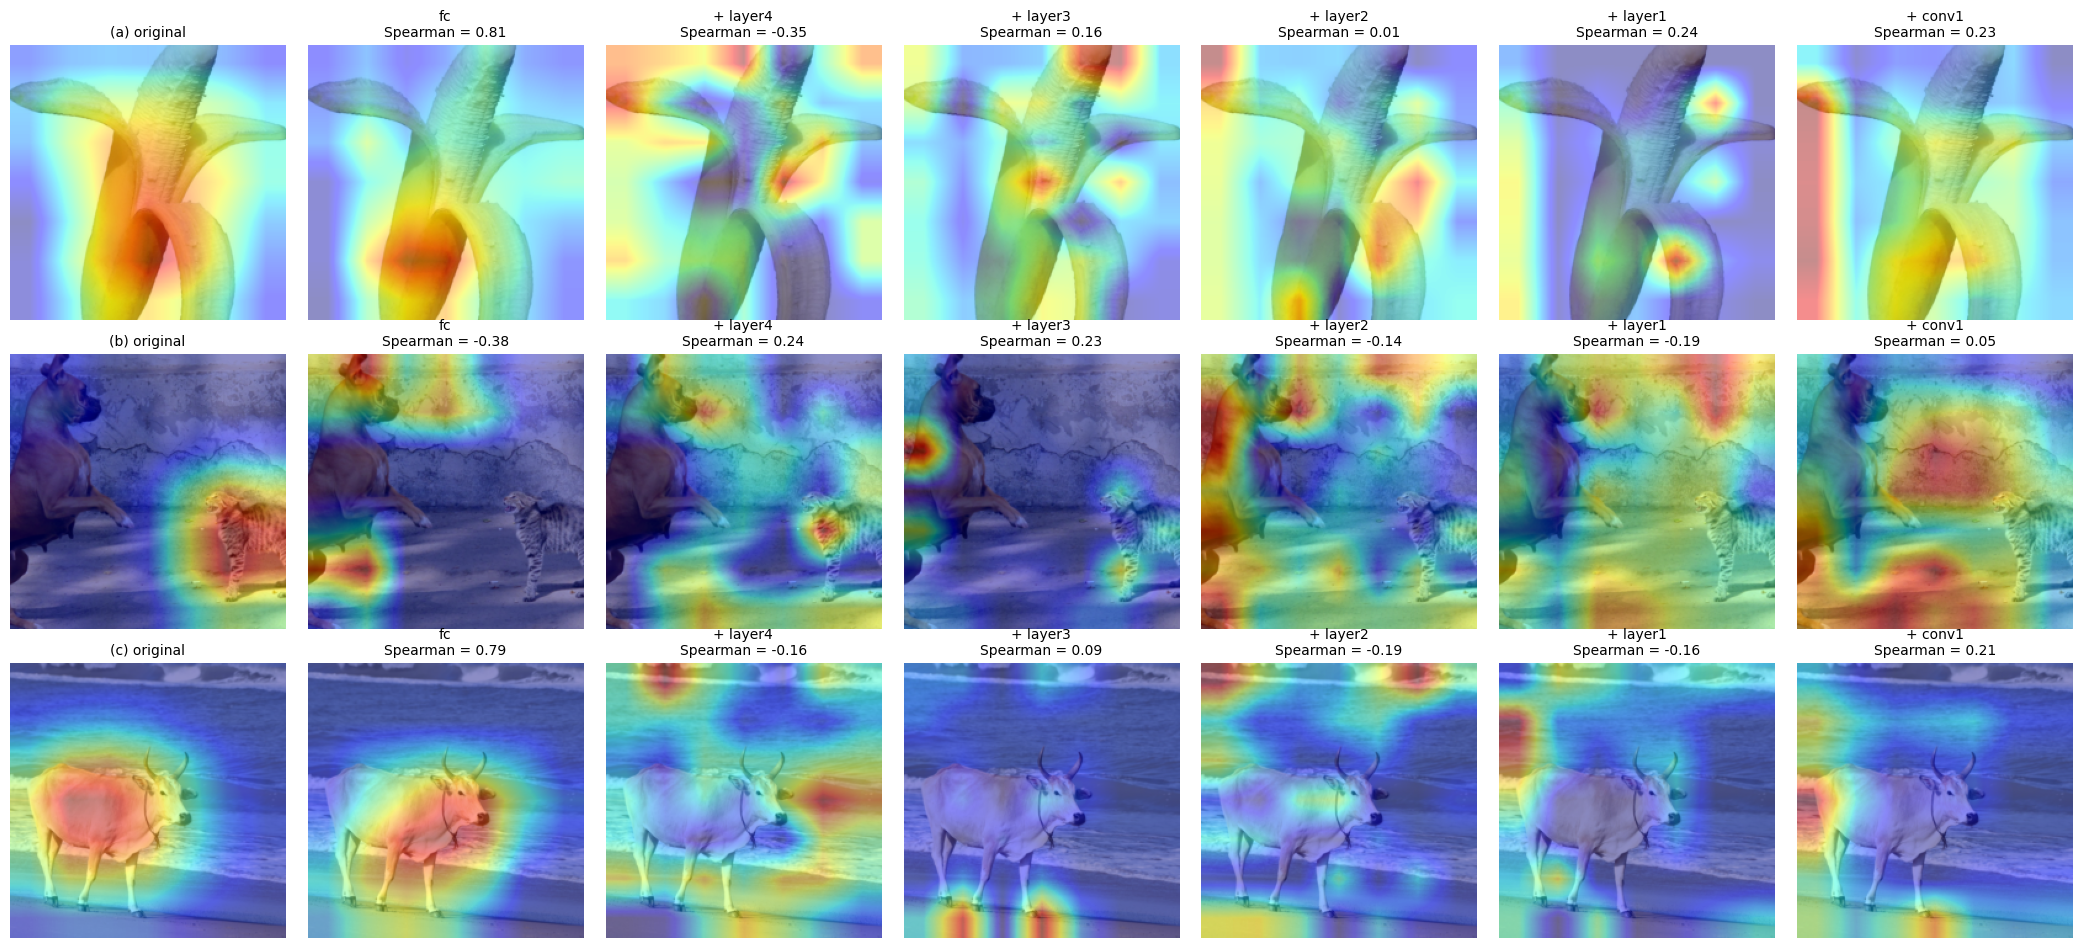

In [35]:
def spearman_seguro(a, b):
    a, b = np.ravel(a), np.ravel(b)
    if np.ptp(a) == 0 or np.ptp(b) == 0:
        return np.nan                                  # mapa constante (por ejemplo, todo 0 tras la ReLU)
    return spearmanr(a, b)[0]

ETAPAS = [("fc", ["fc"]), ("layer4", ["layer4"]), ("layer3", ["layer3"]),
          ("layer2", ["layer2"]), ("layer1", ["layer1"]), ("conv1", ["conv1"])]
modelo_casc = copy.deepcopy(modelo).eval()
gradcam_casc = GradCAM(modelo_casc, modelo_casc.layer4)
torch.manual_seed(SEED)
CASC, filas, filas_pre, filas_pred = {}, [], [], []
for etapa, bloques in ETAPAS:
    for b in bloques:
        for sub in getattr(modelo_casc, b).modules():
            if hasattr(sub, "reset_parameters"):
                sub.reset_parameters()                  # inicialización aleatoria por defecto de PyTorch
    fila, fila_pre, fila_pred = {"etapa": f"+ {etapa}" if etapa != "fc" else "fc"}, {"etapa": etapa}, {"etapa": etapa}
    for k in IMAGENES:
        r = gradcam_casc(X_IMG[k], TOP1[k])              # misma clase del modelo original, no la nueva predicción
        CASC[(etapa, k)] = r
        fila[k] = spearman_seguro(r["L_7"], GC[k]["L_7"])
        fila_pre[k] = spearman_seguro(r["L_lineal"], GC[k]["L_lineal"])
        with torch.no_grad():
            nueva = int(modelo_casc(X_IMG[k]).argmax())
        fila_pred[k] = CATEGORIAS[nueva]
    filas.append(fila); filas_pre.append(fila_pre); filas_pred.append(fila_pred)

tabla_42 = pd.DataFrame(filas).set_index("etapa")
tabla_42.columns = [f"({k}) {CATEGORIAS[TOP1[k]]}" for k in IMAGENES]
print("Spearman entre el Grad-CAM 7 × 7 de cada etapa y el original:"); display(tabla_42)
tabla_42_pre = pd.DataFrame(filas_pre).set_index("etapa")
print("Extra — Spearman sin ReLU:"); display(tabla_42_pre)
print("Extra — nueva clase top-1 del modelo aleatorizado:"); display(pd.DataFrame(filas_pred).set_index("etapa"))
debajo = {}
for k, colname in zip(IMAGENES, tabla_42.columns):
    bajo = tabla_42.index[(tabla_42[colname] < 0.3) | tabla_42[colname].isna()]
    debajo[k] = bajo[0] if len(bajo) else "nunca"
print("Primera etapa con Spearman < 0.3 (o mapa constante):", debajo)
gradcam_casc.quitar()

fig, axes = plt.subplots(3, 7, figsize=(21, 9.5))
for fila_ax, k in zip(axes, IMAGENES):
    superponer(fila_ax[0], IMG[k], GC[k]["L_224"].numpy(), f"({k}) original")
    for ax, (etapa, _) in zip(fila_ax[1:], ETAPAS):
        L = CASC[(etapa, k)]["L_224"].numpy()
        rho = tabla_42.loc[f"+ {etapa}" if etapa != "fc" else "fc"].iloc[list(IMAGENES).index(k)]
        superponer(ax, IMG[k], np.nan_to_num(L), f"{'+ ' if etapa != 'fc' else ''}{etapa}\nSpearman = {rho:.2f}")
plt.tight_layout(); guardar_fig("t4_2_cascada"); mostrar()
RES["task4_2"] = {"spearman": tabla_42.to_dict(), "spearman_sin_relu": tabla_42_pre.to_dict(),
                  "nueva_top1": filas_pred, "primera_etapa_bajo_03": debajo}

### 4.3b (cálculos) — Qué predice $\alpha_k^c=w_k^c/Z$ cuando solo se aleatoriza `fc`
Con solo `fc` aleatorizado, las activaciones $A^k$ no cambian y el mapa pasa a ser $\mathrm{ReLU}(\sum_k \tilde w_k^c A^k)/Z$ con pesos $\tilde w$ aleatorios. Se verifica que $\alpha_k^c=\tilde w_k^c/Z$ y que $A$ no cambió, y se simula la distribución del Spearman esperado con 500 inicializaciones aleatorias de `fc` (solo hace falta $A$; no se necesita retropropagar).

In [36]:
modelo_fc = copy.deepcopy(modelo).eval()
torch.manual_seed(SEED)
modelo_fc.fc.reset_parameters()
gc_fc = GradCAM(modelo_fc, modelo_fc.layer4)
lin = torch.nn.Linear(512, 1000)
filas = []
for k in IMAGENES:
    r = gc_fc(X_IMG[k], TOP1[k])
    w_nuevo = modelo_fc.fc.weight.detach()[TOP1[k]]
    err_alpha = (r["alpha"] - w_nuevo / 49).abs().max().item()
    err_A = (r["A"] - GC[k]["A"]).abs().max().item()
    A = GC[k]["A"].reshape(512, 49)
    sims = []
    torch.manual_seed(SEED)
    for _ in range(500):
        lin.reset_parameters()
        m = F.relu(lin.weight.detach()[TOP1[k]] @ A)               # ReLU(sum_k w~_k A^k) en las 49 posiciones
        sims.append(spearman_seguro(m, GC[k]["L_7"]))
    sims = np.array(sims)
    filas.append({"imagen": k, "máx|alpha - w~/Z|": err_alpha, "máx|A nueva - A original|": err_A,
                  "Spearman etapa fc": tabla_42.iloc[0, list(IMAGENES).index(k)],
                  "simulación: media": np.nanmean(sims), "simulación: p5": np.nanpercentile(sims, 5),
                  "simulación: p95": np.nanpercentile(sims, 95), "simulación: % mapas constantes": np.isnan(sims).mean() * 100})
gc_fc.quitar()
tabla_43b = pd.DataFrame(filas)
display(tabla_43b)
RES["task4_3b"] = tabla_43b.to_dict(orient="records")

,imagen,máx|alpha - w~/Z|,máx|A nueva - A original|,Spearman etapa fc,simulación: media,simulación: p5,simulación: p95,simulación: % mapas constantes
0,a,1.74623e-10,0,0.810816,0.144186,-0.464926,0.792946,5.8
1,b,1.16415e-10,0,-0.382984,0.0793476,-0.502691,0.725536,1.8
2,c,1.74623e-10,0,0.793093,0.145203,-0.590845,0.813456,3.2


---
## Guardar resultados de la entrega final

In [37]:
with open("resultados/resultados_final.json", "w", encoding="utf-8") as fh:
    json.dump(a_float(RES), fh, ensure_ascii=False, indent=2, default=str)
print("Guardado resultados/resultados_final.json y figuras/:", sorted(os.listdir("figuras")))

Guardado resultados/resultados_final.json y figuras/: ['t1_1_bbox_c.png', 't1_1_imagenes.png', 't1_2_gradcam.png', 't1_3_cam_vs_gradcam.png', 't1_4b_iou.png', 't1_4c_prueba_causal.png', 't2_2d_beeswarm.png', 't2_2d_waterfall_aprobado.png', 't2_2d_waterfall_rechazado.png', 't3_1_lime_clientes.png', 't3_5a_jaccard_vs_nef.png', 't3_5b_discrepancia.png', 't4_1_deletion_insertion.png', 't4_2_cascada.png', 't4_3a_deletion_gris_vs_desenfocada.png']
